# Which categorisation of inter-syllable gaps does prosody support?

**Occurrence** = the gap between two consecutive syllables. Each gap has a 0/1 vector of prosodic features: the acoustic features of the syllable before and after, and the perceptual features (prominence, Begin/End of Foot, Group, Package, Period) of the tokens they belong to.

**Candidate categorisations** = every syntactic descriptor of the gap (constituency, dependency, POS of the words), alone and combined in pairs. We don't decide in advance which gap types exist: each candidate is tested the same way.

**Test** = the stability analysis of the word notebook. Each gap's prosodic neighbours are found once. For each candidate we ask how often a gap's neighbours share its category, compared with random relabellings, and summarise with the same kappa.

**Units** = the gaps themselves. In the word study, the occurrences of a lexeme were pooled into one unit. A gap has no lexical identity of that kind (word pairs are too rare to pool), and every candidate must be tested on the same units, so each gap is its own unit.

Then, for the best candidate:
* its stability matrix, showing where its categories overlap (Step 5);
* the split tests of the word notebook's Step 2, asking which descriptor divides each category (Step 6);
* the refined categorisation and its stability matrix (Step 7).

In [54]:
from collections import Counter, defaultdict
from itertools import combinations
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"

# ── Prosodic features ────────────────────────────────────────────────────
#   "all" : acoustic + perceptual | "acoustic" : syllable measures only | "perceptual" : prominence + Begin/End only
FEATURE_SET = "all"
PAIR_FEATURES = True         # NEW: add features of the pair of syllables (F0 jump, duration ratio), see Step 1
ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")
UNIT_LEVELS = ("Foot", "Group", "Package", "Period")
TOKEN_ANCHOR = "syllable"        # "token": both syllables get their token's Begin/End
                              # "syllable": Begin only on the token's first syllable, End only on its last
MIN_FEATURE_OCC = 10          # a feature seen fewer times is noise
DROP_UNMEASURED = True        # keep only gaps whose two syllables have every acoustic measure,
                              # so that a 0 always means "absent", never "not measured"
EXCLUDE_PILES = False         # True: drop gaps touching a disfluent pile
PILE_RELS = {"repair", "conj:dicto", "conj:reform"}

# ── Neighbourhoods (as SIM_THRESHOLD / MAX_NEIGHBOURS in the word notebook) ──
MAX_NEIGHBOURS = 20
# MAX_DIFF = 1                  # neighbours differ on at most 6 features (one measure changing value = 2 differences)
SIM_THRESHOLD = 0.7
CHUNK = 1000                  # gaps compared at a time (memory)

# ── Tests ────────────────────────────────────────────────────────────────
MIN_CAT = 30                  # a category (or a split group) needs at least this many gaps
MAX_COMBINATION = 2           # candidates: descriptors alone (1) and in pairs (2); 3 adds triples (slow)
N_PERM_RANK = 100             # shuffles per candidate when ranking all candidates
N_PERM, ALPHA = 1000, 0.05    # shuffles for the detailed tests, as in the word notebook
KAPPA_MIN = 0.20              # Landis & Koch (1977): below 0.20 = "slight"
SEED = 0

## Step 0 — read the treebank
Syllables are the `X.n` subnodes. Their HEAD column lists the token(s) they belong to (two for a fused syllable such as [se] in *c'est*). Syllables are kept in file order: in about 20 sentences the time stamps contradict the token order, which looks like alignment errors.

In [55]:
def _misc(field):
    return dict(kv.split("=", 1) for kv in field.split("|") if "=" in kv) if field != "_" else {}


def read_sentences(path):
    """One dict per sentence with prosodic annotation:
    tokens    {id: dict(form, upos, head, rel, misc)}
    syllables [dict(id, toks, misc), ...] in file order."""
    def parse(meta, lines):
        tokens, syllables = {}, []
        for c in lines:
            if "-" in c[0]:
                continue
            m = _misc(c[9])
            if "." in c[0]:
                toks = [int(t) for t in c[6].split("|") if t.isdigit()]
                if toks:
                    syllables.append(dict(id=c[0], toks=toks, misc=m))
            else:
                tokens[int(c[0])] = dict(form=c[1], upos=c[3], rel=c[7], misc=m,
                                         head=int(c[6]) if c[6].isdigit() else 0)
        # first and last syllable of each token
        first, last = {}, {}
        for k, sy in enumerate(syllables):
            for t in sy["toks"]:
                first.setdefault(t, k)
                last[t] = k
        return dict(sent_id=meta.get("sent_id"), text=meta.get("text", ""),
                    tokens=tokens, syllables=syllables, first=first, last=last)

    meta, lines = {}, []
    with open(path, encoding="utf8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if lines and meta.get("prosodic_annotation") == "yes":
                    yield parse(meta, lines)
                meta, lines = {}, []
            elif line.startswith("#"):
                if " = " in line:
                    k, v = line[2:].split(" = ", 1)
                    meta[k] = v
            else:
                lines.append(line.split("\t"))
    if lines and meta.get("prosodic_annotation") == "yes":
        yield parse(meta, lines)


SENTS = list(read_sentences(TREEBANK_PATH))
print(f"{len(SENTS)} sentences with prosodic annotation, "
      f"{sum(len(s['syllables']) for s in SENTS)} syllables")

2979 sentences with prosodic annotation, 43827 syllables


## Step 0b — the gaps
A gap sits between syllable *k* and syllable *k*+1. **L** is the token of the syllable before (the last one, for a fused syllable) and **R** the token of the syllable after. L = R: the gap is inside a word. R = L+1: the gap is a word boundary. Anything else (a token with no syllable in between) is skipped.

In [56]:
def pile_words(tokens):
    """Words in a disfluent pile: they bear a pile relation, or govern one (as in the word notebook)."""
    out = set()
    for i, t in tokens.items():
        if t["rel"] in PILE_RELS:
            out |= {i, t["head"]}
    return out


GAPS, skipped = [], Counter()
for s in SENTS:
    tok, syl = s["tokens"], s["syllables"]
    piles = pile_words(tok) if EXCLUDE_PILES else set()
    for k in range(len(syl) - 1):
        L, R = max(syl[k]["toks"]), min(syl[k + 1]["toks"])
        if L not in tok or R not in tok:
            skipped["syllable without token"] += 1
        elif L != R and R != L + 1:
            skipped["not adjacent tokens"] += 1
        elif L in piles or R in piles:
            skipped["disfluent pile"] += 1
        else:
            GAPS.append(dict(sent=s, k=k, L=L, R=R,
                             gap_type="word-internal" if L == R else "word boundary"))

print(f"{len(GAPS)} gaps kept | skipped: {dict(skipped)}")
print(Counter(g["gap_type"] for g in GAPS))

40661 gaps kept | skipped: {'not adjacent tokens': 206}
Counter({'word boundary': 26309, 'word-internal': 14352})


## Step 1 — one binary vector per gap
Continuous measures are cut into three corpus-wide quantile bins, with the 0.0 sentinel treated as missing, as in the word notebook. Feature names start with `before:` or `after:`.

**NEW (Sylvain, 15 Oct).** With `PAIR_FEATURES = True`, two features describe the pair of syllables: **F0 jump** = F0 after − F0 before (semitones from the utterance mean), and **duration ratio** = log2(duration after / duration before). Each is cut into corpus tertiles (`pair:F0_jump=down / level / up`, `pair:Dur_ratio=after_shorter / similar / after_longer`). They only use measures every kept gap already has, so the gaps are the same with or without them.

In [57]:
BIN_LABELS = {
    "SemitonesFromUtteranceMean": ["F0_low", "F0_mid", "F0_high"],
    "Duration":                   ["Dur_short", "Dur_mid", "Dur_long"],
}
PROMINENCE_RANK = {"Weak": 1, "Strong": 2}       # 0, Pause and Overlap are not prominences


def _number(value):
    """Float, or None for missing values and the 0.0 sentinel."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return None
    return None if v == 0.0 else v


thresholds = {}
for name in BIN_LABELS:
    vals = np.array([v for s in SENTS for sy in s["syllables"]
                     if (v := _number(sy["misc"].get(name))) is not None])
    thresholds[name] = np.quantile(vals, [1 / 3, 2 / 3])
    lab = BIN_LABELS[name]
    print(f"  {name}: ≤{thresholds[name][0]:.2f} → {lab[0]} | ≤{thresholds[name][1]:.2f} → {lab[1]} | above → {lab[2]}")


def acoustic(sy):
    """Acoustic features of one syllable."""
    out = []
    for name in ACOUSTIC_MEASURES:
        v = sy["misc"].get(name)
        if name in BIN_LABELS:
            x = _number(v)
            if x is not None:
                out.append(BIN_LABELS[name][int(np.searchsorted(thresholds[name], x))])
        elif v not in (None, "X"):
            out.append(f"{name}={v}")
    return out


def prominence(s, k):
    """ProminenceFinal if syllable k is the last syllable of its token, ProminenceInitial
    if it is the first one; for a one-syllable token, the stronger of the two."""
    best = None
    for t in s["syllables"][k]["toks"]:
        if t not in s["tokens"]:
            continue
        m = s["tokens"][t]["misc"]
        vals = ([m.get("ProminenceFinal")] if s["last"][t] == k else []) + \
               ([m.get("ProminenceInitial")] if s["first"][t] == k else [])
        for v in vals:
            if v in PROMINENCE_RANK and (best is None or PROMINENCE_RANK[v] > PROMINENCE_RANK[best]):
                best = v
    return best


def unit_position(value):
    """Begin / In / Last / Unique. Period values carry * and - markers (e.g. '*I*'), which we strip."""
    return {"B": "Begin", "I": "In", "L": "Last", "U": "Unique"}.get((value or "").strip("*-")[:1])


def unit_features(s, k, t):
    """Begin / End of each prosodic unit for token t, seen from syllable k."""
    m, out = s["tokens"][t]["misc"], []
    for level in UNIT_LEVELS:
        pos = unit_position(m.get(level))
        begin, end = pos in ("Begin", "Unique"), pos in ("Last", "Unique")
        if TOKEN_ANCHOR == "syllable":
            begin, end = begin and s["first"][t] == k, end and s["last"][t] == k
        out += [f"{level}=Begin"] * begin + [f"{level}=End"] * end
    return out


def gap_features(g):
    s, k, feats = g["sent"], g["k"], []
    for side, kk, t in (("before", k, g["L"]), ("after", k + 1, g["R"])):
        if FEATURE_SET in ("all", "acoustic"):
            feats += [f"{side}:{f}" for f in acoustic(s["syllables"][kk])]
        if FEATURE_SET in ("all", "perceptual"):
            p = prominence(s, kk)
            feats += [f"{side}:Prominence={p}"] if p else []
            feats += [f"{side}:{f}" for f in unit_features(s, kk, t)]
    if PAIR_FEATURES and FEATURE_SET in ("all", "acoustic"):           # NEW: the pair of syllables
        for name, labs in PAIR_LABELS.items():
            v = g["pair"][name]
            if v is not None:
                feats.append(f"pair:{name}={labs[int(np.searchsorted(pair_thresholds[name], v))]}")
    return feats


# ── NEW (Sylvain, 15 Oct): how the syllable after differs from the syllable before ──
PAIR_LABELS = {"F0_jump": ["down", "level", "up"],                         # F0 after − F0 before (semitones)
               "Dur_ratio": ["after_shorter", "similar", "after_longer"]}  # log2(duration after / duration before)


def pair_values(g):
    a, b = (g["sent"]["syllables"][kk]["misc"] for kk in (g["k"], g["k"] + 1))
    f0a, f0b = (_number(m.get("SemitonesFromUtteranceMean")) for m in (a, b))
    da, db = (_number(m.get("Duration")) for m in (a, b))
    return {"F0_jump": None if f0a is None or f0b is None else f0b - f0a,
            "Dur_ratio": None if da is None or db is None else np.log2(db / da)}


for g in GAPS:
    g["pair"] = pair_values(g)
pair_thresholds = {}
for name, labs in PAIR_LABELS.items():
    pair_thresholds[name] = np.quantile([g["pair"][name] for g in GAPS if g["pair"][name] is not None],
                                        [1 / 3, 2 / 3])
    if PAIR_FEATURES:
        lo, hi = pair_thresholds[name]
        print(f"  pair {name}: ≤{lo:.2f} → {labs[0]} | ≤{hi:.2f} → {labs[1]} | above → {labs[2]}")


GAP_FEATS = [gap_features(g) for g in GAPS]
feat_counts = Counter(f for fs in GAP_FEATS for f in set(fs))
kept = sorted(f for f, n in feat_counts.items() if n >= MIN_FEATURE_OCC)
idx2feature = dict(enumerate(kept))
feature2idx = {f: i for i, f in idx2feature.items()}

# GAP_M[i, j] = 1 if gap i has feature j
GAP_M = np.zeros((len(GAPS), len(kept)), dtype=np.float32)
for a, fs in enumerate(GAP_FEATS):
    for f in fs:
        j = feature2idx.get(f)
        if j is not None:
            GAP_M[a, j] = 1

# a gap with no feature at all cannot be placed: drop it
has_feats = GAP_M.sum(1) > 0
GAPS = [g for g, keep in zip(GAPS, has_feats) if keep]
GAP_M = GAP_M[has_feats]


def measured(g):
    """Both syllables have every acoustic measure."""
    sy = g["sent"]["syllables"]
    return all((_number(sy[kk]["misc"].get(n)) is not None) if n in BIN_LABELS
               else sy[kk]["misc"].get(n) not in (None, "X")
               for kk in (g["k"], g["k"] + 1) for n in ACOUSTIC_MEASURES)


n_before = len(GAPS)
if DROP_UNMEASURED and FEATURE_SET != "perceptual":
    keep = np.array([measured(g) for g in GAPS])
    GAPS, GAP_M = [g for g, k in zip(GAPS, keep) if k], GAP_M[keep]
print(f"{GAP_M.shape[0]} gaps × {GAP_M.shape[1]} features "
      f"({(~has_feats).sum()} without features and {n_before - len(GAPS)} not fully measured dropped); "
      f"{GAP_M.sum(1).mean():.1f} features per gap on average")
print(", ".join(kept))

  SemitonesFromUtteranceMean: ≤-1.25 → F0_low | ≤0.59 → F0_mid | above → F0_high
  Duration: ≤131.00 → Dur_short | ≤199.00 → Dur_mid | above → Dur_long
  pair F0_jump: ≤-0.90 → down | ≤0.61 → level | above → up
  pair Dur_ratio: ≤-0.28 → after_shorter | ≤0.48 → similar | above → after_longer
33411 gaps × 56 features (300 without features and 6950 not fully measured dropped); 16.4 features per gap on average
after:AvgHeightGlo=H, after:AvgHeightGlo=L, after:AvgHeightGlo=M, after:Dur_long, after:Dur_mid, after:Dur_short, after:F0_high, after:F0_low, after:F0_mid, after:Foot=Begin, after:Foot=End, after:Group=Begin, after:Group=End, after:Package=Begin, after:Package=End, after:Period=Begin, after:Period=End, after:PitchRangeGlo=H, after:PitchRangeGlo=L, after:PitchRangeGlo=M, after:Prominence=Strong, after:Prominence=Weak, after:SlopeGlo=Fall, after:SlopeGlo=Flat, after:SlopeGlo=Rise, before:AvgHeightGlo=H, before:AvgHeightGlo=L, before:AvgHeightGlo=M, before:Dur_long, before:Dur_mid, be

In [58]:
idx2feature

{0: 'after:AvgHeightGlo=H',
 1: 'after:AvgHeightGlo=L',
 2: 'after:AvgHeightGlo=M',
 3: 'after:Dur_long',
 4: 'after:Dur_mid',
 5: 'after:Dur_short',
 6: 'after:F0_high',
 7: 'after:F0_low',
 8: 'after:F0_mid',
 9: 'after:Foot=Begin',
 10: 'after:Foot=End',
 11: 'after:Group=Begin',
 12: 'after:Group=End',
 13: 'after:Package=Begin',
 14: 'after:Package=End',
 15: 'after:Period=Begin',
 16: 'after:Period=End',
 17: 'after:PitchRangeGlo=H',
 18: 'after:PitchRangeGlo=L',
 19: 'after:PitchRangeGlo=M',
 20: 'after:Prominence=Strong',
 21: 'after:Prominence=Weak',
 22: 'after:SlopeGlo=Fall',
 23: 'after:SlopeGlo=Flat',
 24: 'after:SlopeGlo=Rise',
 25: 'before:AvgHeightGlo=H',
 26: 'before:AvgHeightGlo=L',
 27: 'before:AvgHeightGlo=M',
 28: 'before:Dur_long',
 29: 'before:Dur_mid',
 30: 'before:Dur_short',
 31: 'before:F0_high',
 32: 'before:F0_low',
 33: 'before:F0_mid',
 34: 'before:Foot=Begin',
 35: 'before:Foot=End',
 36: 'before:Group=Begin',
 37: 'before:Group=End',
 38: 'before:Packag

## Step 2 — the syntactic descriptors (the material for the candidate categorisations)

**Words.** `gap_type` (inside a word or a word boundary), `pos_before`, `pos_after`.

**Dependency.** The flux of a gap is the set of dependencies with one end on each side; for a gap inside a word, those passing over the word. An arrow gives the direction: `det←` means the governor is after the gap and the dependent before it (*la ‖ journée*), `comp:obj→` the reverse (*de ‖ Jésus*). Without crossing dependencies the flux is nested like brackets, and the innermost dependency (the shortest) links the head of the smallest group around the gap to the subgroup on the other side. `dep_inner_rel` is its relation, `dep_inner_dir` its direction, `dep_inner` both.

**Constituency** is read off the dependency tree, with one level per dependent, whatever its relation. A head combines first with its dependents on the right, closest first, then with those on the left: [la [première [journée [de Jésus]]]]. The full projection is labelled by its head (NP, PP, AP, AdvP, CP for *que* + clause…) and the levels below it are N', V'… For a verb, the levels that include the subject are **S** and the largest level without it is the **VP**.

For a word boundary:
* `inside` is the smallest constituent containing both sides;
* `between` gives the largest constituents ending just before and starting just after the gap, within that one. A bare head is written as its category (`V`, `N`, `P`…), so `V|NP` is *voit ‖ le chat* and `NP|VP` is *le chat ‖ dort*;
* `n_close` / `n_open` count the phrases (NP, VP, PP, AP, AdvP, CP, S) ending / starting at the gap; a lone determiner or an N' level is not counted.

Constituents are sets of words, not spans. A constituent "ends at the gap" only if all its words are before it, so a phrase made discontinuous by a distant apposition does not count as closing.

Relation subtypes after `@` are dropped (`mod@relcl` → `mod`).

**NEW (Sylvain, 15 Oct): relation families.** `dep_family` groups the relation of the innermost dependency: determiner, subject, complement, modifier, udep, coordination / apposition, flat / compound, disfluency (`reparandum`, `conj:reform`) and periphery (discourse, dislocated, parataxis, vocative, unk…). `dep_family_gov` splits the complements by the class of their governor: V = verb or auxiliary (*voit ‖ le chat*), P = preposition (*de ‖ Jésus*), C = *que*, *si* (*que ‖ nous venons*), other. It splits the modifiers the same way: V (*parle ‖ lentement*), N = noun, pronoun or numeral (*journée ‖ intéressante*), other. Gaps inside a word are `inside a word`. The two are not in `BASE`, so they are not in the Step 4 ranking.

In [59]:
ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


def cap(n, top=4):
    return f"{top}+" if n >= top else str(n)


def dependency_descriptors(g):
    tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
    arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
    if L == R:
        cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
    else:
        cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
    cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
    back = sum(1 for h, d, _ in cross if d < h)
    labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
    return dict(
        flux_size=cap(len(cross)),
        flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
        dep_inner=labels[0] if labels else "none",
        dep_inner_rel=labels[0][:-1] if labels else "none",
        dep_inner_dir=labels[0][-1] if labels else "none",
        flux_stack=" · ".join(labels) if labels else "none",
    )


HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
              "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
              "CCONJ": "Conj", "INTJ": "Intj"}
PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
                "D": "D", "Conj": "Conj", "Intj": "Intj"}


def head_label(t):
    return HEAD_LABEL.get(t["upos"], t["upos"])


def constituents(tok):
    """(set of word ids, label) for every constituent, with no intermediate levels.
    Each word's projection (the word and everything it governs) is one constituent,
    labelled by its head: NP, PP, AP, AdvP, CP (que + clause), D (determiner)…
    A verb or auxiliary with a subject projects S, and the part after the subject is
    a VP; a verb without a subject projects a VP."""
    kids = defaultdict(list)
    for i, t in tok.items():
        if t["head"] in tok:
            kids[t["head"]].append(i)
    sub = {i: {i} for i in tok}
    for i in tok:                                   # add each word to all its ancestors
        a, steps = tok[i]["head"], 0
        while a in tok and steps < len(tok):
            sub[a].add(i)
            a, steps = tok[a]["head"], steps + 1
    out = []
    for i, t in tok.items():
        h = head_label(t)
        if h != "V":
            out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
            continue
        subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
        if not subj:
            out.append((frozenset(sub[i]), "VP"))
            continue
        out.append((frozenset(sub[i]), "S"))
        subj_end = max(max(sub[k]) for k in subj)
        if subj_end < i:                             # subject before the verb: VP = what follows it
            vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
            out.append((frozenset(vp), "VP"))
    return out



for s in SENTS:
    s["constituents"] = constituents(s["tokens"])


def is_phrase(label):
    """NP, VP, PP, AP, AdvP, CP, S — not a bar level (N') or a word-level label (D, Conj)."""
    return label == "S" or label.endswith("P")


def constituency_descriptors(g):
    s, L, R = g["sent"], g["L"], g["R"]
    if L == R:
        return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
    C = s["constituents"]
    around = [c for c in C if L in c[0] and R in c[0]]
    if not around:
        return dict(inside="none", between="none", n_close="0", n_open="0")
    enc = min(around, key=lambda c: len(c[0]))
    within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
    ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
    starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
    left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
    right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
    return dict(inside=enc[1], between=f"{left}|{right}",
                n_close=cap(sum(is_phrase(c[1]) and L in c[0] and max(c[0]) == L for c in C)),
                n_open=cap(sum(is_phrase(c[1]) and R in c[0] and min(c[0]) == R for c in C)))


def context(g, width=4):
    """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
    s, L, R = g["sent"], g["L"], g["R"]
    tok = s["tokens"]
    before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
    after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
    if L == R:
        sy = s["syllables"]
        mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
    else:
        mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
    return " ".join(before + [mid] + after)


rows = []
for g in GAPS:
    tok = g["sent"]["tokens"]
    pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
    d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
             pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
             context=context(g))
    d.update(constituency_descriptors(g))
    d.update(dependency_descriptors(g))
    rows.append(d)
GAPS_DF = pd.DataFrame(rows)
GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

# The descriptors the candidate categorisations are built from. Combinations such as
# dep_inner (= rel × dir), pos_pair (= before × after) or between × inside appear as pairs.
BASE = ["gap_type", "inside", "between", "n_close", "n_open",
        "dep_inner_rel", "dep_inner_dir", "flux_size", "pos_before", "pos_after"]


FUNCTION_POS = {"DET", "ADP", "PRON", "AUX", "CCONJ", "SCONJ"}
internal = GAPS_DF["gap_type"] == "word-internal"
for side in ("before", "after"):
    GAPS_DF[f"class_{side}"] = np.where(GAPS_DF[f"pos_{side}"].isin(FUNCTION_POS), "function", "content")
GAPS_DF["after_word_class"] = np.where(internal, "word-internal",
                                        "after a " + GAPS_DF["class_before"] + " word")
BASE += ["class_before", "class_after"]

print(GAPS_DF[BASE].nunique().to_string())


# ── NEW (Sylvain, 15 Oct): relation families, complements and modifiers split by governor ──
FAMILY = {"det": "determiner", "subj": "subject", "comp": "complement", "mod": "modifier", "udep": "udep",
          "cc": "coordination / apposition", "conj": "coordination / apposition",
          "flat": "flat / compound", "compound": "flat / compound"}
GOV_CLASS = {"VERB": "V", "AUX": "V", "NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "N",
             "ADP": "P", "SCONJ": "C"}
SPLIT_BY_GOVERNOR = {"complement": ("V", "P", "C"), "modifier": ("V", "N")}   # any other governor: "other"


def family(rel):
    if rel in ("reparandum", "conj:reform", "conj:dicto", "repair"):
        return "disfluency"
    if rel in ("conj:appos", "mod:appos"):
        return "coordination / apposition"
    return FAMILY.get(rel.split(":")[0], "periphery")     # discourse, dislocated, parataxis, vocative, unk…


def relation_family(g):
    """dep_family and dep_family_gov of the innermost dependency (word boundaries only)."""
    if g["L"] == g["R"]:
        return "inside a word", "inside a word"
    tok, L = g["sent"]["tokens"], g["L"]
    cross = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items()
             if t["head"] in tok and min(t["head"], d) <= L < max(t["head"], d)]
    if not cross:
        return "none", "none"
    h, d, rel = min(cross, key=lambda a: abs(a[0] - a[1]))
    fam, gov = family(rel), GOV_CLASS.get(tok[h]["upos"], "other")
    if fam in SPLIT_BY_GOVERNOR:
        return fam, f"{fam} of {gov if gov in SPLIT_BY_GOVERNOR[fam] else 'other'}"
    return fam, fam


GAPS_DF[["dep_family", "dep_family_gov"]] = pd.DataFrame([relation_family(g) for g in GAPS], index=GAPS_DF.index)
print()
print(GAPS_DF["dep_family_gov"].value_counts().to_string())


gap_type           2
inside            12
between          260
n_close            5
n_open             5
dep_inner_rel     32
dep_inner_dir      3
flux_size          5
pos_before        14
pos_after         14
class_before       2
class_after        2

dep_family_gov
inside a word                11492
complement of V               3698
complement of P               2924
determiner                    2813
modifier of V                 2262
subject                       2099
periphery                     1832
modifier of N                 1560
coordination / apposition     1547
udep                           938
disfluency                     778
modifier of other              610
complement of C                367
flat / compound                259
complement of other            232


In [60]:
# ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


# def cap(n, top=4):
#     return f"{top}+" if n >= top else str(n)


# def dependency_descriptors(g):
#     tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
#     arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
#     if L == R:
#         cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
#     else:
#         cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
#     cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
#     back = sum(1 for h, d, _ in cross if d < h)
#     labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
#     return dict(
#         flux_size=cap(len(cross)),
#         flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
#         dep_inner=labels[0] if labels else "none",
#         dep_inner_dir=labels[0][-1] if labels else "none",
#         flux_stack=" · ".join(labels) if labels else "none",
#     )


# HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
#               "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
#               "CCONJ": "Conj", "INTJ": "Intj"}
# PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
#                 "D": "D", "Conj": "Conj", "Intj": "Intj"}


# def head_label(t):
#     return HEAD_LABEL.get(t["upos"], t["upos"])


# def constituents(tok):
#     """(set of word ids, label) for every constituent of the sentence. Constituents are
#     sets rather than spans, so that a non-projective dependency (e.g. a distant
#     apposition) does not make a phrase swallow the words in between."""
#     kids = defaultdict(list)
#     for i, t in tok.items():
#         if t["head"] in tok:
#             kids[t["head"]].append(i)
#     sub = {i: {i} for i in tok}
#     for i in tok:                                   # add each word to all its ancestors
#         a, steps = tok[i]["head"], 0
#         while a in tok and steps < len(tok):
#             sub[a].add(i)
#             a, steps = tok[a]["head"], steps + 1
#     out = []
#     for i, t in tok.items():
#         h = head_label(t)
#         if h != "V":
#             out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
#             continue
#         subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
#         if not subj:
#             out.append((frozenset(sub[i]), "VP"))
#             continue
#         out.append((frozenset(sub[i]), "S"))
#         subj_end = max(max(sub[k]) for k in subj)
#         if subj_end < i:                             # subject before the verb: VP = what follows it
#             vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
#             out.append((frozenset(vp), "VP"))
#     return out


# for s in SENTS:
#     s["constituents"] = constituents(s["tokens"])


# def constituency_descriptors(g):
#     s, L, R = g["sent"], g["L"], g["R"]
#     if L == R:
#         return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
#     C = s["constituents"]
#     around = [c for c in C if L in c[0] and R in c[0]]
#     if not around:
#         return dict(inside="none", between="none", n_close="0", n_open="0")
#     enc = min(around, key=lambda c: len(c[0]))
#     within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
#     ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
#     starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
#     left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
#     right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
#     return dict(inside=enc[1], between=f"{left}|{right}",
#                 n_close=cap(sum(L in c[0] and max(c[0]) == L for c in C)),
#                 n_open=cap(sum(R in c[0] and min(c[0]) == R for c in C)))


# def context(g, width=4):
#     """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
#     s, L, R = g["sent"], g["L"], g["R"]
#     tok = s["tokens"]
#     before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
#     after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
#     if L == R:
#         sy = s["syllables"]
#         mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
#     else:
#         mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
#     return " ".join(before + [mid] + after)


# rows = []
# for g in GAPS:
#     tok = g["sent"]["tokens"]
#     pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
#     d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
#              pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
#              context=context(g))
#     d.update(constituency_descriptors(g))
#     d.update(dependency_descriptors(g))
#     rows.append(d)
# GAPS_DF = pd.DataFrame(rows)
# GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

# DESCRIPTORS = {
#     "constituency": ["inside", "between", "between_in", "n_close", "n_open"],
#     "dependency":   ["dep_inner", "dep_inner_dir", "flux_size", "flux_dir", "flux_stack"],
#     "words":        ["gap_type", "pos_before", "pos_after", "pos_pair"],
# }
# print(GAPS_DF[[c for cols in DESCRIPTORS.values() for c in cols]].nunique().to_string())
# BASE = ["gap_type", "inside", "between", "n_close", "n_open",
#         "dep_inner_rel", "dep_inner_dir", "flux_size", "pos_before", "pos_after"]

In [61]:
# Sanity check: every gap of one sentence with both descriptions
cols = ["context", "inside", "between", "n_close", "n_open", "dep_inner", "pos_before", "pos_after", "gap_type"]
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    print(GAPS_DF[GAPS_DF.sent_id == GAPS_DF.sent_id.iloc[0]][cols].to_string(index=False))

                                             context inside         between n_close n_open   dep_inner pos_before pos_after      gap_type
               c' est la ‖ première journée de Jésus     NP            D|AP       0      1        det←        DET       ADJ word boundary
       c' est la première[pR@‖mjER] journée de Jésus   word (inside a word)       0      0        det←        ADJ       ADJ word-internal
           c' est la première ‖ journée de Jésus que     NP            AP|N       1      0        mod←        ADJ      NOUN word boundary
        est la première journée[ZuR‖ne] de Jésus que   word (inside a word)       0      0 comp:cleft→       NOUN      NOUN word-internal
         est la première journée ‖ de Jésus que nous     NP            N|PP       0      1       udep→       NOUN       ADP word boundary
      la première journée de ‖ Jésus que nous venons     PP            P|NP       0      1   comp:obj→        ADP     PROPN word boundary
    première journée de Jésus[Ze‖z

## Step 3 — prosodic neighbourhoods (computed once)
**Distance** between two gaps = the number of features on which they differ. A feature both lack counts as an agreement, like a feature both have.

**Neighbours** of a gap = the `MAX_NEIGHBOURS` closest gaps that differ on at most `MAX_DIFF` features (not the gap itself). Equal distances are ordered at random, with a fixed seed.

**Weight** of a neighbour = its similarity (1 − distance / number of features), divided by the row total so each gap's weights sum to 1, as in `neighbour_weights()`.

Nothing here depends on any categorisation.

cosine ignores features that both gaps lack, whereas the current distance counts a shared absence as an agreement.

In [62]:
# def gap_neighbours(M, rng): # to use when using max_diff
#     """Neighbour graph of a set of gaps, as three arrays (rows, cols, weights):
#     gap rows[e] has neighbour cols[e] with weight weights[e]."""
#     M = M.astype(np.float32)
#     n, F = M.shape
#     k = min(MAX_NEIGHBOURS, n - 1)
#     if k < 1:
#         return np.array([], int), np.array([], int), np.array([])
#     ones = M.sum(1)
#     rows, cols, weights = [], [], []
#     for a in range(0, n, CHUNK):
#         B = M[a:a + CHUNK]
#         D = ones[a:a + CHUNK, None] + ones[None, :] - 2 * (B @ M.T)   # number of differing features
#         r = np.arange(len(B))
#         D[r, a + r] = np.inf                                           # not itself
#         order = D + rng.random(D.shape, dtype=np.float32) * 0.5          # random order among equal distances
#         nearest = np.argpartition(order, k - 1, axis=1)[:, :k]
#         d = np.take_along_axis(D, nearest, axis=1)
#         ok = d <= MAX_DIFF
#         sim = np.where(ok, 1 - np.minimum(d, F) / F, 0.0)
#         total = sim.sum(1, keepdims=True)
#         w = np.divide(sim, total, out=np.zeros_like(sim), where=total > 0)
#         rows.append(np.repeat(a + r, k).reshape(len(B), k)[ok])
#         cols.append(nearest[ok])
#         weights.append(w[ok])
#     return np.concatenate(rows), np.concatenate(cols), np.concatenate(weights)

# Neighbours as in the word paper: cosine similarity ≥ SIM_THRESHOLD, at most MAX_NEIGHBOURS,
# each neighbour weighted by its similarity (weights of a gap sum to 1).
# One addition: gaps are single 0/1 vectors, so many are identical (30% have an exact twin);
# ties are broken at random with a fixed seed, as before.
# In the config cell, replace MAX_DIFF = 6 with:  SIM_THRESHOLD = 0.7
def gap_neighbours(M, rng):
    """Neighbour graph of a set of gaps, as three arrays (rows, cols, weights):
    gap rows[e] has neighbour cols[e] with weight weights[e]."""
    M = M.astype(np.float32)
    n = len(M)
    k = min(MAX_NEIGHBOURS, n - 1)
    if k < 1:
        return np.array([], int), np.array([], int), np.array([])
    norm = np.sqrt(M.sum(1))
    rows, cols, weights = [], [], []
    for a in range(0, n, CHUNK):
        B = M[a:a + CHUNK]
        sim = (B @ M.T) / (norm[a:a + CHUNK, None] * norm[None, :])      # cosine similarity
        r = np.arange(len(B))
        sim[r, a + r] = -np.inf                                         # not itself
        order = -sim + rng.random(sim.shape, dtype=np.float32) * 1e-4   # random order among equal similarities
        nearest = np.argpartition(order, k - 1, axis=1)[:, :k]
        s = np.take_along_axis(sim, nearest, axis=1)
        ok = s >= SIM_THRESHOLD
        s = np.where(ok, s, 0.0)
        total = s.sum(1, keepdims=True)
        w = np.divide(s, total, out=np.zeros_like(s), where=total > 0)
        rows.append(np.repeat(a + r, k).reshape(len(B), k)[ok])
        cols.append(nearest[ok])
        weights.append(w[ok])
    return np.concatenate(rows), np.concatenate(cols), np.concatenate(weights)

def restrict(nb, keep):
    """The neighbour graph among the kept gaps only (keep: boolean array), re-indexed."""
    rows, cols, w = nb
    new = np.full(len(keep), -1)
    new[keep] = np.arange(keep.sum())
    e = keep[rows] & keep[cols]
    return new[rows[e]], new[cols[e]], w[e]


t0 = time.time()
NB = gap_neighbours(GAP_M, np.random.default_rng(SEED))
n_nbrs = np.bincount(NB[0], minlength=len(GAPS))
print(f"{time.time() - t0:.0f}s | gaps with at least one neighbour: {(n_nbrs > 0).sum()} / {len(GAPS)}; "
      f"neighbours per gap: median {np.median(n_nbrs):.0f}")

13s | gaps with at least one neighbour: 33411 / 33411; neighbours per gap: median 20


## Step 4 — test every candidate categorisation
`stability()` is the word notebook's computation, written so that many shuffles run quickly:
* `p_norm(gap, C)` = share of the gap's neighbour weight that falls in category C, divided by the frequency of C and renormalised;
* `mat[C, C']` = mean `p_norm(gap, C')` over the gaps of C that have neighbours;
* `same` = mean self-stability (diagonal), `chance` = the same after shuffling the labels, `kappa` = (same − chance) / (1 − chance).

A candidate is one descriptor, or the joint value of two (e.g. `dep_inner_rel & pos_before`). Categories with fewer than `MIN_CAT` gaps are left out of that candidate's test rather than pooled into a residual group, so check the `covered` column. Kappa compares candidates with different numbers of categories: splitting a category at random lowers it.

With tens of thousands of gaps, every candidate is significant (p sits at its minimum, 1 / (`N_PERM_RANK` + 1)), so compare the kappas.

In [63]:
def p_norm(nb, labels, n_cats):
    rows, cols, w = nb
    n = len(labels)
    P = np.bincount(rows * n_cats + labels[cols], weights=w, minlength=n * n_cats).reshape(n, n_cats)
    has = P.sum(1) > 0
    S = P / (np.bincount(labels, minlength=n_cats) / n)            # p(gap, C) / freq(C)
    S[has] /= S[has].sum(1, keepdims=True)                            # renormalise -> p_norm
    return S, has


def stability(nb, labels, n_cats):
    """mat[C, C'] = mean p_norm(gap, C') over the gaps of C with neighbours (word notebook)."""
    S, has = p_norm(nb, labels, n_cats)
    Y = sparse.csr_matrix((np.ones(has.sum()), (np.arange(has.sum()), labels[has])),
                          shape=(has.sum(), n_cats))
    counts = np.bincount(labels[has], minlength=n_cats)
    return np.asarray(Y.T @ S[has]) / np.maximum(counts, 1)[:, None], S, has


def mean_diag(nb, labels, n_cats):
    """Mean self-stability over the categories that have gaps with neighbours."""
    S, has = p_norm(nb, labels, n_cats)
    counts = np.bincount(labels[has], minlength=n_cats)
    own = np.bincount(labels[has], weights=S[has, labels[has]], minlength=n_cats)
    present = counts > 0
    return (own[present] / counts[present]).mean()


def categorisation(cols):
    """Category of every gap = joint value of the descriptors in `cols`.
    Returns (keep, labels, cats): gaps in categories with at least MIN_CAT gaps,
    their category numbers, and the category names."""
    lab = GAPS_DF[list(cols)].astype(str).agg(" & ".join, axis=1).to_numpy()
    values, counts = np.unique(lab, return_counts=True)
    cats = sorted(values[counts >= MIN_CAT])
    index = {c: i for i, c in enumerate(cats)}
    keep = np.array([v in index for v in lab])
    return keep, np.array([index[v] for v in lab[keep]]), cats


def kappa_test(nb, labels, n_cats, n_perm, rng):
    same = mean_diag(nb, labels, n_cats)
    null = np.array([mean_diag(nb, rng.permutation(labels), n_cats) for _ in range(n_perm)])
    chance = null.mean()
    return dict(same=same, chance=chance, kappa=(same - chance) / (1 - chance),
                p=(1 + (null >= same).sum()) / (n_perm + 1))


CANDIDATES = [c for size in range(1, MAX_COMBINATION + 1) for c in combinations(BASE, size)]
rng = np.random.default_rng(SEED)
t0, rank_rows = time.time(), []
for cols in CANDIDATES:
    keep, labels, cats = categorisation(cols)
    if len(cats) < 2:
        continue
    res = kappa_test(restrict(NB, keep), labels, len(cats), N_PERM_RANK, rng)
    rank_rows.append(dict(candidate=" & ".join(cols), categories=len(cats),
                          covered=keep.mean(), **res))
RANKING = pd.DataFrame(rank_rows).sort_values("kappa", ascending=False).reset_index(drop=True)
print(f"{len(RANKING)} candidates tested in {time.time() - t0:.0f}s")
with pd.option_context("display.width", 200):
    print(RANKING.head(30).round(3).to_string())

78 candidates tested in 57s
                       candidate  categories  covered   same  chance  kappa     p
0                       gap_type           2    1.000  0.735   0.500  0.470  0.01
1        gap_type & class_before           4    1.000  0.463   0.250  0.284  0.01
2                    class_after           2    1.000  0.633   0.500  0.265  0.01
3                   class_before           2    1.000  0.626   0.500  0.253  0.01
4         gap_type & class_after           4    1.000  0.435   0.250  0.247  0.01
5     class_before & class_after           4    1.000  0.424   0.250  0.232  0.01
6                  dep_inner_dir           3    1.000  0.444   0.333  0.166  0.01
7             gap_type & n_close           6    1.000  0.298   0.167  0.156  0.01
8       gap_type & dep_inner_dir           5    1.000  0.317   0.200  0.147  0.01
9              gap_type & n_open           5    1.000  0.309   0.200  0.136  0.01
10                       n_close           5    1.000  0.306   0.200  

In [64]:
# Each descriptor alone, for reference
with pd.option_context("display.width", 200):
    print(RANKING[~RANKING.candidate.str.contains("&")].round(3).to_string())

        candidate  categories  covered   same  chance  kappa     p
0        gap_type           2    1.000  0.735   0.500  0.470  0.01
2     class_after           2    1.000  0.633   0.500  0.265  0.01
3    class_before           2    1.000  0.626   0.500  0.253  0.01
6   dep_inner_dir           3    1.000  0.444   0.333  0.166  0.01
10        n_close           5    1.000  0.306   0.200  0.133  0.01
14         n_open           4    1.000  0.335   0.250  0.113  0.01
16         inside          12    1.000  0.169   0.083  0.094  0.01
22     pos_before          14    1.000  0.140   0.072  0.074  0.01
24      pos_after          14    1.000  0.138   0.071  0.071  0.01
31      flux_size           5    1.000  0.250   0.200  0.063  0.01
37  dep_inner_rel          24    0.998  0.095   0.042  0.055  0.01
63        between          93    0.962  0.040   0.011  0.029  0.01


In [65]:
def neighbour_guess(cols, only=None):
    """Guess each gap's category from its neighbours and report how often the guess is right.
    The guess is the category with the highest p_norm: the frequency-corrected share of the
    gap's neighbour weight that stability() computes. `only` (True/False for every gap)
    restricts the test to a subset of gaps, e.g. word boundaries."""
    keep, labels, cats = categorisation(cols)
    if only is not None:
        sub = only[keep]
        present = np.unique(labels[sub])
        labels, cats, keep = np.searchsorted(present, labels[sub]), [cats[i] for i in present], keep & only
    nb = restrict(NB, keep)
    _, S, has = stability(nb, labels, len(cats))
    rows, nbr, w = nb
    same = np.bincount(rows, weights=w * (labels[nbr] == labels[rows]), minlength=len(labels))
    guess = S.argmax(1)
    n = np.bincount(labels, minlength=len(cats))
    out = pd.DataFrame({
        "gaps": n,
        "share of all gaps": n / n.sum(),
        "neighbours in the same category": [same[has & (labels == i)].mean() for i in range(len(cats))],
        "guessed right": [(guess[has & (labels == i)] == i).mean() for i in range(len(cats))]},
        index=cats)
    print(f"{' & '.join(cols)}: balanced accuracy {out['guessed right'].mean():.3f} (chance {1 / len(cats):.3f})")
    return out.round(3)


neighbour_guess(("gap_type",))
neighbour_guess(("after_word_class",))
neighbour_guess(("after_word_class",), only=(GAPS_DF["gap_type"] == "word boundary").to_numpy())

gap_type: balanced accuracy 0.801 (chance 0.500)
after_word_class: balanced accuracy 0.676 (chance 0.333)
after_word_class: balanced accuracy 0.744 (chance 0.500)


,gaps,share of all gaps,neighbours in the same category,guessed right
after a content word,10856,0.495,0.612,0.732
after a function word,11063,0.505,0.496,0.755


## Step 5 — the stability matrix of one candidate
**NEW:** `CHOSEN = ("dep_family_gov",)`, the relation families with complements and modifiers split by governor; `("dep_family_gov", "dep_inner_dir")` adds the direction. Set `CHOSEN` to any other candidate, e.g. `("between",)` or `("dep_inner_rel", "dep_inner_dir")`.
The chance matrix is the mean over `N_PERM` shuffles. A category's kappa = (stability − chance) / (1 − chance) on its own diagonal cell.
**Overlaps** are off-diagonal cells clearly above their chance value: gaps of one category whose prosodic neighbours are often in another.

In [66]:
RANKING.candidate.iloc[1]


'gap_type & class_before'

dep_grouped: 9 categories, 33393 gaps (100% covered); mean kappa 0.178
                gaps  stability  chance  kappa
inside a word  11492      0.439   0.145  0.344
group 5         1089      0.316   0.118  0.225
group 4          626      0.300   0.102  0.220
group 6         1288      0.281   0.122  0.181
group 8          258      0.224   0.073  0.163
group 1         1521      0.259   0.125  0.153
group 7         8268      0.265   0.144  0.142
group 2         8792      0.237   0.144  0.108
group 3           59      0.095   0.029  0.068

overlaps:
                       observed  chance  excess
gaps of neighbours in                          
group 3 group 2           0.194   0.144    0.05


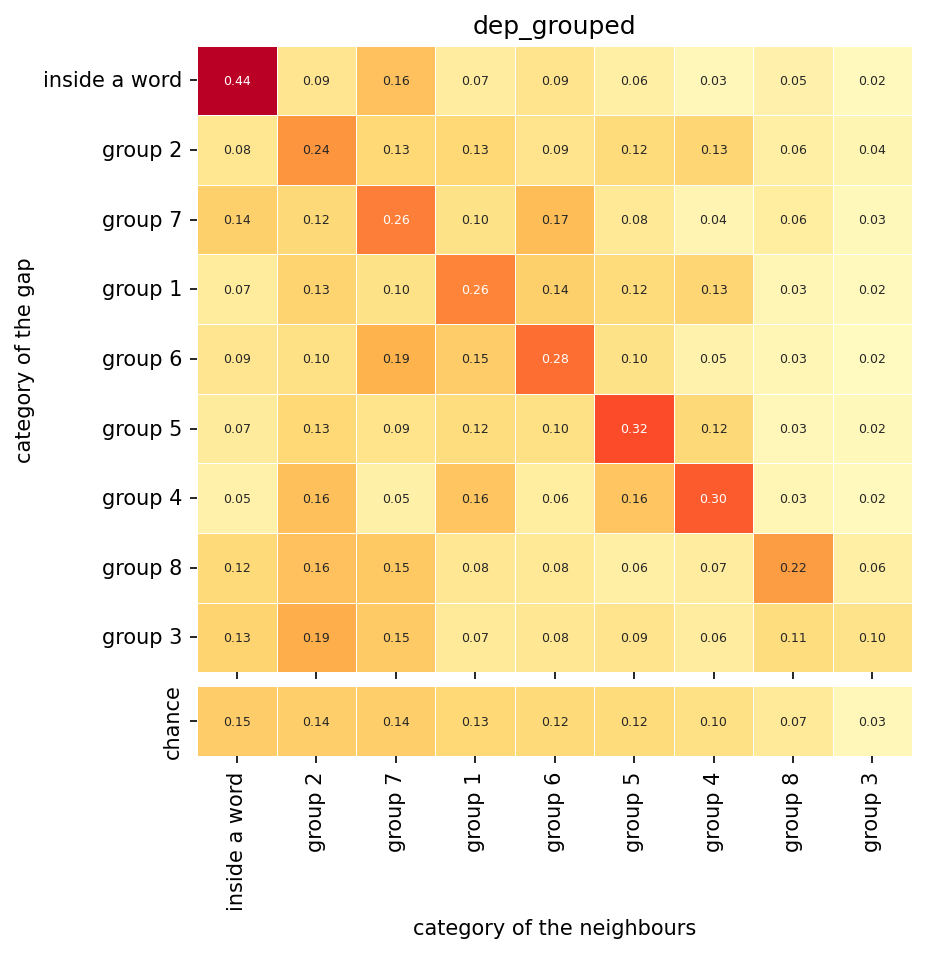

In [79]:
# CHOSEN = tuple(RANKING.candidate.iloc[0].split(" & "))
# CHOSEN = "dep_inner_dir"
# CHOSEN = ("after_word_class",)
# CHOSEN = ("dep_inner_dir",)
# CHOSEN = ("dep_family_gov",)                      # NEW: relation families, comp / mod split by governor
# CHOSEN = ("dep_family_gov", "dep_inner_dir")    # … and the direction of the relation
CHOSEN = ("dep_grouped",)
OVERLAP_MIN = 0.05            # report off-diagonal cells at least this far above chance
MAX_SHOWN = 40                # largest categories shown in the heatmap


def full_stability(nb, labels, cats, n_perm, rng):
    C = len(cats)
    observed, S, has = stability(nb, labels, C)
    chance = np.zeros((C, C))
    for _ in range(n_perm):
        chance += stability(nb, rng.permutation(labels), C)[0]
    chance /= n_perm
    table = pd.DataFrame({"gaps": np.bincount(labels, minlength=C),
                          "stability": np.diag(observed), "chance": np.diag(chance)}, index=cats)
    table["kappa"] = (table["stability"] - table["chance"]) / (1 - table["chance"])
    obs_df, ch_df = pd.DataFrame(observed, cats, cats), pd.DataFrame(chance, cats, cats)
    over = (obs_df - ch_df).stack()
    over = over[(over.index.get_level_values(0) != over.index.get_level_values(1)) & (over >= OVERLAP_MIN)]
    overlaps = pd.DataFrame({"observed": obs_df.stack()[over.index], "chance": ch_df.stack()[over.index],
                             "excess": over}).sort_values("excess", ascending=False)
    overlaps.index.names = ["gaps of", "neighbours in"]
    return obs_df, ch_df, table, overlaps


def plot_stability(obs_df, ch_df, table, title, vmax=0.5):
    shown = table.sort_values("gaps", ascending=False).index[:MAX_SHOWN]
    obs, chance_col = obs_df.loc[shown, shown], ch_df.loc[shown, shown].mean(axis=0)
    n = len(shown)
    fig, (ax, axc) = plt.subplots(2, 1, figsize=(0.35 * n + 3, 0.35 * n + 3), dpi=150, sharex=True,
                                  gridspec_kw={"height_ratios": [n, 1], "hspace": 0.04})
    kw = dict(cmap="YlOrRd", vmin=0, vmax=vmax, annot=n <= 25, fmt=".2f", annot_kws={"size": 6},
              cbar=False, linewidths=0.3, linecolor="white")
    sns.heatmap(obs, ax=ax, **kw)
    sns.heatmap(chance_col.to_frame().T, ax=axc, yticklabels=["chance"], **kw)
    axc.tick_params(axis="x", rotation=90)
    ax.set_title(title); ax.set_ylabel("category of the gap"); axc.set_xlabel("category of the neighbours")
    return fig


keep, labels, cats = categorisation(CHOSEN)
nb_chosen = restrict(NB, keep)
obs_df, ch_df, table, overlaps = full_stability(nb_chosen, labels, cats, N_PERM, np.random.default_rng(SEED))
print(f"{' & '.join(CHOSEN)}: {len(cats)} categories, {keep.sum()} gaps ({100 * keep.mean():.0f}% covered); "
      f"mean kappa {table['kappa'].mean():.3f}")
print(table.sort_values("kappa", ascending=False).round(3).to_string())
print("\noverlaps:")
print(overlaps.round(3).head(25).to_string())
plot_stability(obs_df, ch_df, table, " & ".join(CHOSEN));

## Step 6 — which descriptor (if any) divides each category? (the word notebook's Step 2)
Within one category, neighbours are recomputed among its own gaps only, as in `split_test()`. Each descriptor not already in `CHOSEN` is tried as a split.

A split is eligible only if every value it takes in the category has at least `MIN_CAT` gaps. Rare values are not pooled into a residual group.

The best split with p < `ALPHA` and kappa ≥ `KAPPA_MIN` is kept.

Kappas are lower here than in the word study, where each unit pooled many occurrences; a single gap is a noisier unit. So `KAPPA_MIN = 0.20` is strict at this level: lower it to see weaker splits.

In [68]:
N_PERM_SPLIT = N_PERM         # lower it (e.g. 200) for a quicker first look


def split_tests(cat_index, rng):
    rows = np.where(keep)[0][labels == cat_index]           # gap indices of this category
    sub = GAPS_DF.iloc[rows]
    nb = gap_neighbours(GAP_M[rows], rng)
    out = []
    for attr in BASE:
        if attr in CHOSEN:
            continue
        values = sub[attr].astype(str).to_numpy()
        names, counts = np.unique(values, return_counts=True)
        if len(names) < 2 or counts.min() < MIN_CAT:
            continue
        lab = np.searchsorted(names, values)
        res = kappa_test(nb, lab, len(names), N_PERM_SPLIT, rng)
        out.append(dict(category=cats[cat_index], attr=attr,
                        groups=", ".join(f"{v}:{n}" for v, n in sorted(zip(names, counts), key=lambda x: -x[1])),
                        **res))
    return pd.DataFrame(out)


t0 = time.time()
rng = np.random.default_rng(SEED)
SPLIT_RESULTS, SPLIT = {}, {}
for ci, cat in enumerate(cats):
    df = split_tests(ci, rng)
    if len(df):
        df = df.sort_values("kappa", ascending=False).reset_index(drop=True)
    SPLIT_RESULTS[cat] = df
    ok = df[(df["p"] < ALPHA) & (df["kappa"] >= KAPPA_MIN)] if len(df) else df
    SPLIT[cat] = ok.iloc[0]["attr"] if len(ok) else None
print(f"{time.time() - t0:.0f}s")

with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    for cat in cats:
        print(f"\n{cat}: split = {SPLIT[cat] or 'none'}")
        if len(SPLIT_RESULTS[cat]):
            print(SPLIT_RESULTS[cat][["attr", "groups", "same", "chance", "kappa", "p"]].round(3).to_string(index=False))

24s

complement of C: split = none
       attr                   groups  same  chance  kappa     p
class_after function:329, content:38 0.586   0.495  0.181 0.001
  flux_size 1:226, 2:67, 3:44, 4+:30 0.270   0.246  0.032 0.054

complement of P: split = none
       attr                       groups  same  chance  kappa     p
class_after  content:1664, function:1260 0.581    0.50  0.162 0.001
  flux_size 1:1326, 2:901, 3:439, 4+:258 0.256    0.25  0.009 0.043

complement of V: split = class_before
         attr                                                                            groups  same  chance  kappa     p
 class_before                                                       content:2378, function:1320 0.607   0.500  0.215 0.001
dep_inner_dir                                                                     →:3207, ←:491 0.601   0.500  0.203 0.001
  class_after                                                       function:2029, content:1669 0.585   0.500  0.169 0.001
dep_inn

## Step 7 — the refined categorisation and its stability matrix (the word notebook's Step 3)

25 refined categories (from 15); smallest has 36 gaps
mean kappa 0.067 (before refinement 0.085)
                                              gaps  stability  chance  kappa
inside a word | class_before=content         10658      0.239   0.047  0.201
disfluency | class_before=function             359      0.189   0.038  0.157
periphery | dep_inner_dir=→                   1089      0.162   0.044  0.124
flat / compound | dep_inner_rel=flat           223      0.133   0.034  0.102
inside a word | class_before=function          834      0.139   0.043  0.101
coordination / apposition | dep_inner_dir=→    626      0.137   0.042  0.099
coordination / apposition | dep_inner_dir=←    921      0.136   0.043  0.097
determiner | class_before=function            2700      0.118   0.046  0.075
udep                                           938      0.112   0.043  0.072
complement of P                               2924      0.109   0.046  0.066
subject | class_before=function               1729      

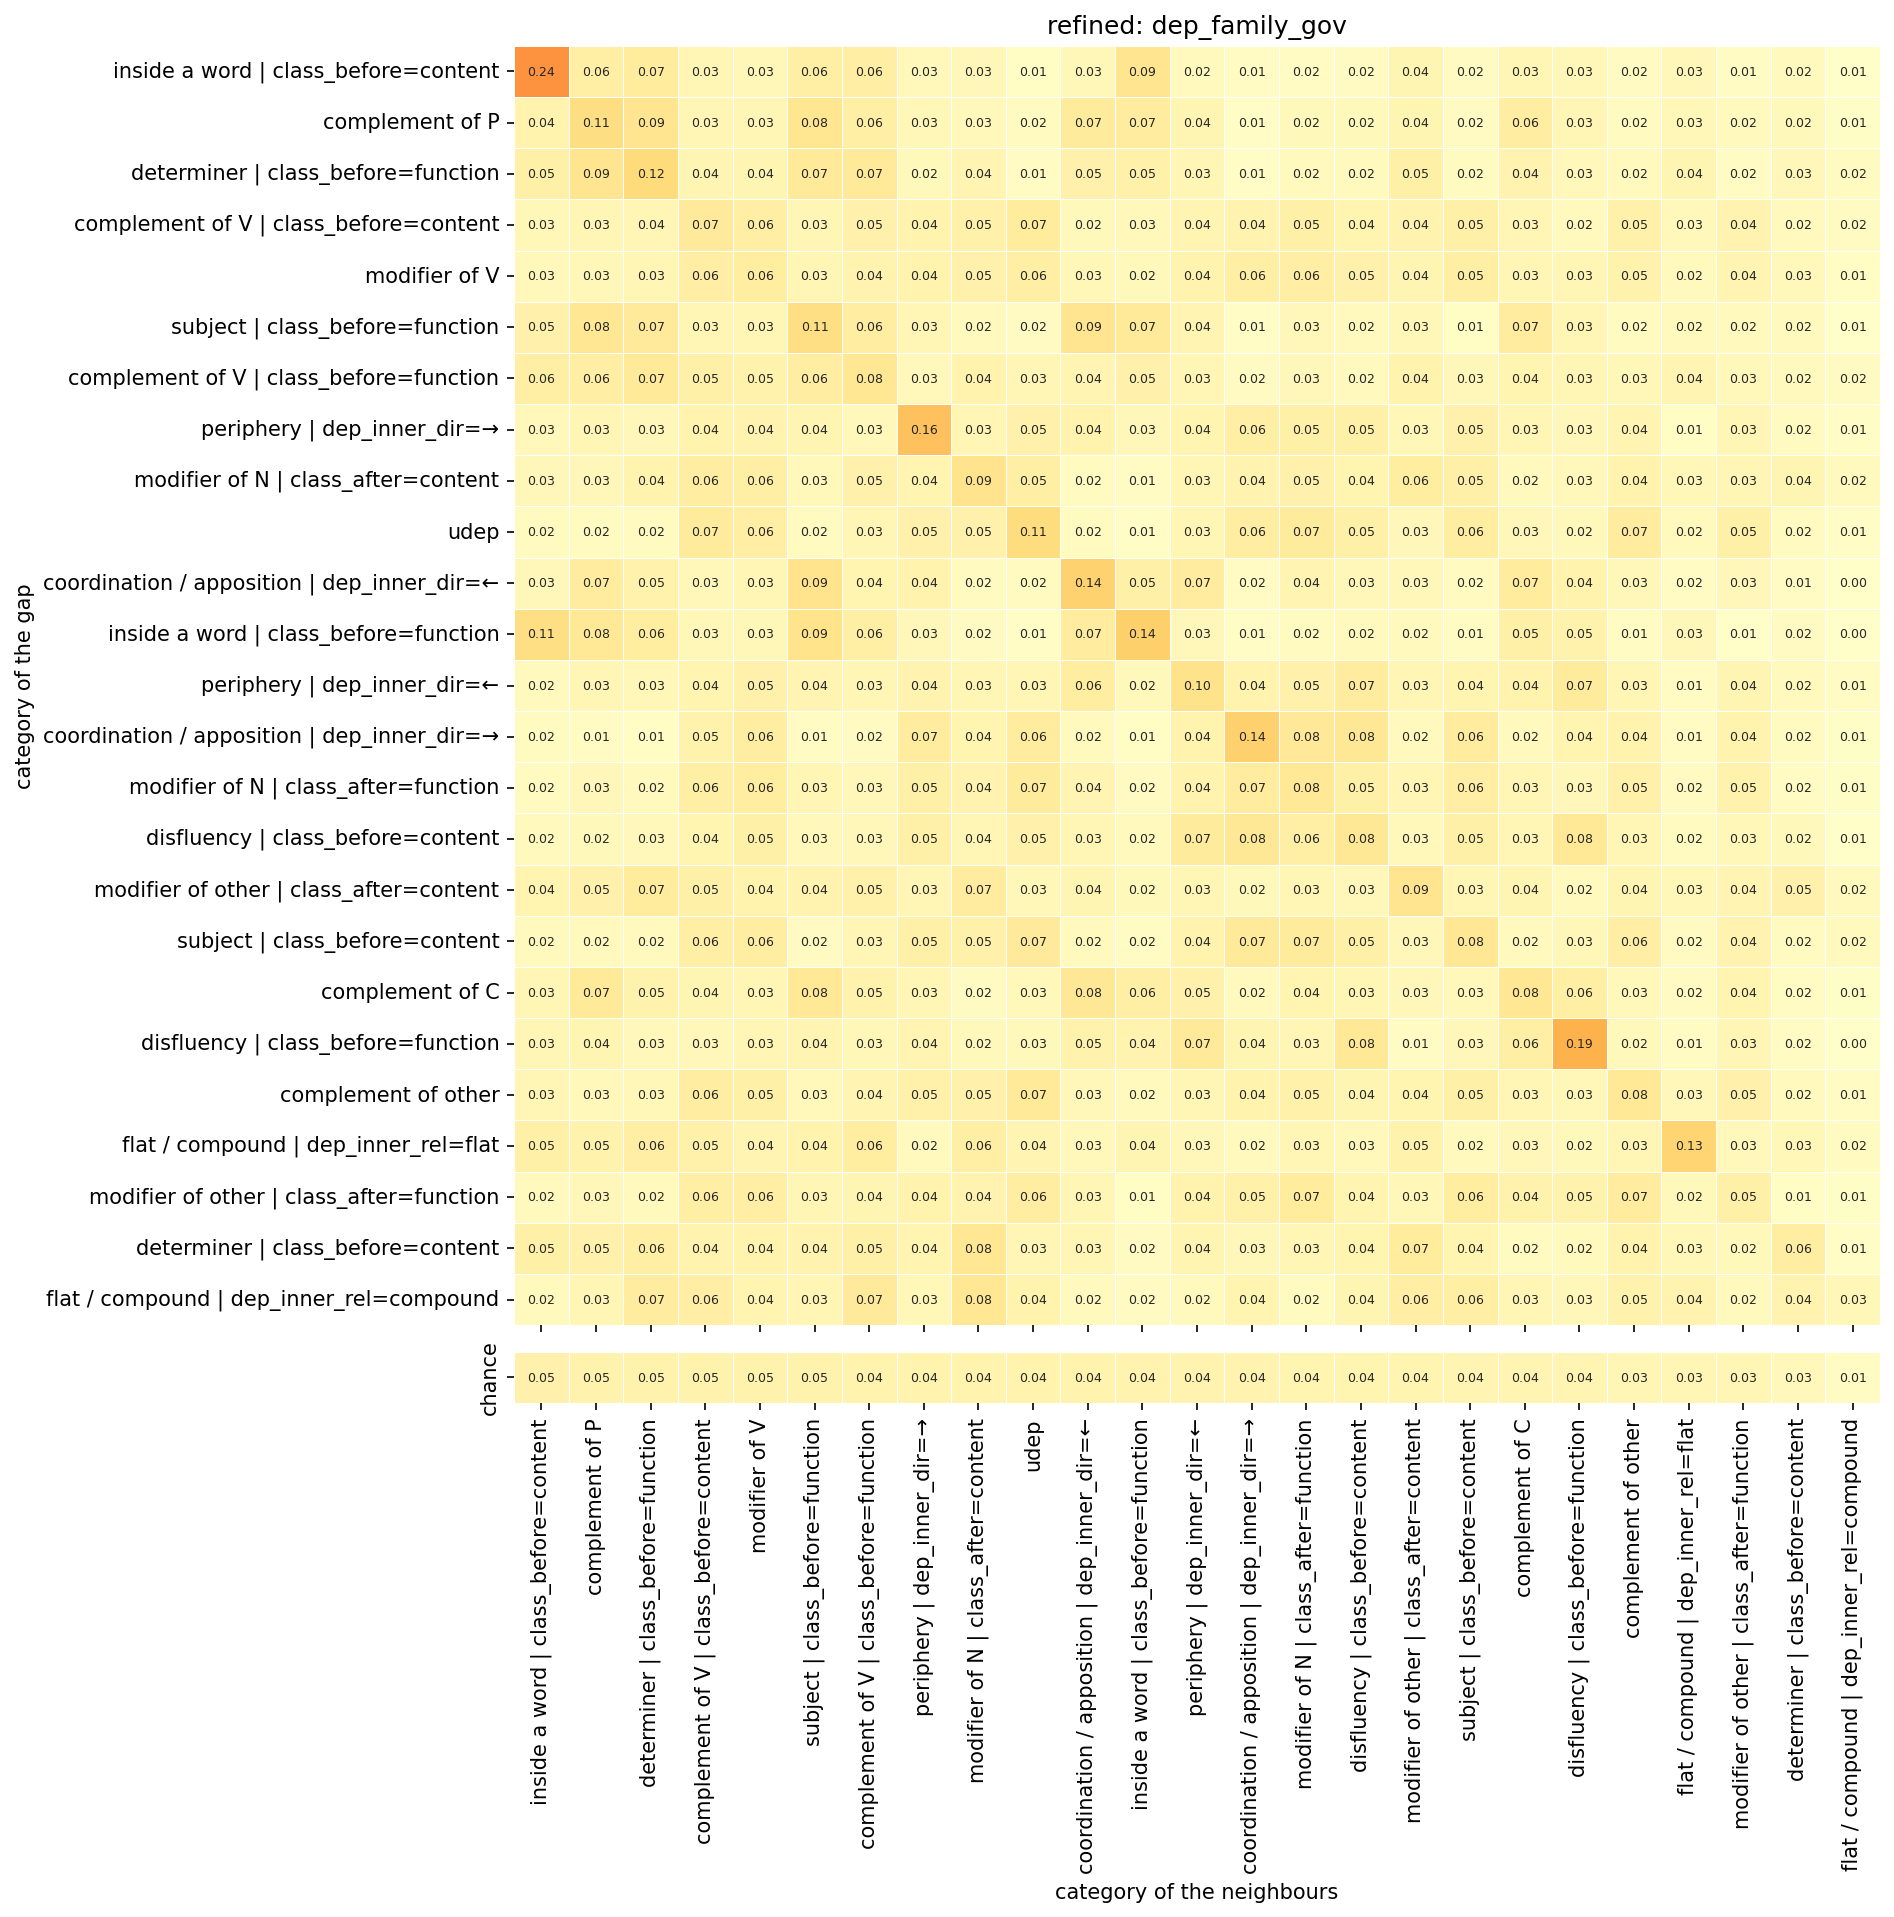

In [69]:
def refined(i_gap, cat):
    attr = SPLIT[cat]
    return cat if attr is None else f"{cat} | {attr}={GAPS_DF.iloc[i_gap][attr]}"


gap_ids = np.where(keep)[0]
ref = np.array([refined(i, cats[c]) for i, c in zip(gap_ids, labels)])
ref_names, ref_counts = np.unique(ref, return_counts=True)
REF_CATS = list(ref_names)
ref_labels = np.searchsorted(ref_names, ref)
print(f"{len(REF_CATS)} refined categories (from {len(cats)}); smallest has {ref_counts.min()} gaps")

obs_ref, ch_ref, table_ref, overlaps_ref = full_stability(nb_chosen, ref_labels, REF_CATS, N_PERM,
                                                          np.random.default_rng(SEED))
print(f"mean kappa {table_ref['kappa'].mean():.3f} (before refinement {table['kappa'].mean():.3f})")
print(table_ref.sort_values("kappa", ascending=False).round(3).to_string())
print("\noverlaps:")
print(overlaps_ref.round(3).head(25).to_string())
plot_stability(obs_ref, ch_ref, table_ref, "refined: " + " & ".join(CHOSEN));

In [70]:
# Examples of gaps from one category (change the name)
example_cat = table.sort_values("kappa", ascending=False).index[0]
sel = gap_ids[labels == cats.index(example_cat)]
for ex in GAPS_DF.iloc[sel]["context"].sample(min(10, len(sel)), random_state=SEED):
    print("·", ex)

· étaient vos vos lectures[lEk‖tyR]
· aller à la province[pRO‖ve~s] pour des études
· allez avec Messi[mE‖si] qui va chercher
· pensée préalable au langage[la~‖gaZ] qui est en
· j' ai trouvé cet[se‖ta~] endroit Olkaloo où
· ça faisait[f2‖zE] partie des institutions
· effectivement sur le hublot[y‖blo] et également sur
· est quel livre alors[vRa‖lOR]
· Rachida Dati écrit aussi[o‖si] Libération Champagne pour
· pas de livres politiques[pO‖li] là


# Part 2 — following the meeting with Sylvain (15 October)
Part 1 has three changes, marked `NEW`:
* **Step 1:** `PAIR_FEATURES = True` adds two features of the pair of syllables (F0 jump, duration ratio). Set it to `False` for the original 50 features.
* **Step 2:** `dep_family` and `dep_family_gov` are the relation families, with complements and modifiers split by the class of their governor.
* **Step 5:** `CHOSEN = ("dep_family_gov",)`, so Steps 5–7 show the stability matrix, the split tests and the refined categories of these families.

The steps below show what pulls two categories together and what keeps them apart (Step 8), group the categories that prosody cannot tell apart (Step 9, optional), and ask whether prominence can be recovered from the acoustics alone (Step 10).

## Step 8 — what pulls two categories together, and what keeps them apart?
The word notebook's `shared_table()` and `plot_overlap()`, for the categories of Step 5.
* A category's **profile** is the share of its gaps that carry each feature.
* A feature that almost every gap has says nothing about why two categories are close, so each profile is measured against the **average category**: the mean of the profiles, each category counting once. For a feature *f*, d₀(*f*) = profile of C0 − average, d₁(*f*) = profile of C1 − average.
* *f* contributes d₀(*f*) · d₁(*f*) / (‖d₀‖ ‖d₁‖). The contribution is **shared** (> 0) when both categories deviate from the average in the same direction, and **opposed** (< 0) when they deviate in opposite directions.
* Summed over all features, this is the cosine between d₀ and d₁, the **resemblance** (−1 to 1). `region_table()` splits it by region: before or after the gap, perceptual or acoustic, and the pair features.
* **Bridge gaps** of C0 are the gaps whose neighbourhood holds at least as much C1 as C0 (Step 4's p_norm).

The figure shows one feature per row. For values that exclude each other (`Dur_short / mid / long`…), it keeps the one with the largest contribution. Begin and End of a unit are kept apart, since a one-word foot is both.

resemblance subject / complement of V:
                     shared  opposed    net
region                                     
before / perceptual   0.034   -0.478 -0.444
before / acoustic     0.109   -0.001  0.108
pair                  0.013   -0.003  0.010
after / acoustic      0.029   -0.002  0.027
after / perceptual    0.036   -0.058 -0.022
total                 0.221   -0.541 -0.320

subject:
  · le livre que lit ‖ Pascale Ferran
  · il ‖ faut s' appeler Rachida
  · et euh ça ‖ s' arrête lorsque la
  · on ‖ vous retrouve pour un
  · très renforcée que ça ‖ nous nous nous revienne

complement of V:
  · est sur le terrain ‖ que se gagne ou
  · dit que ça avait ‖ augmenté d' à peu
  · tous ces linges sont ‖ propres
  · euh réaliser euh vraiment ‖ ce que c' était
  · maintenant on va ‖ faire une interview vaudeville


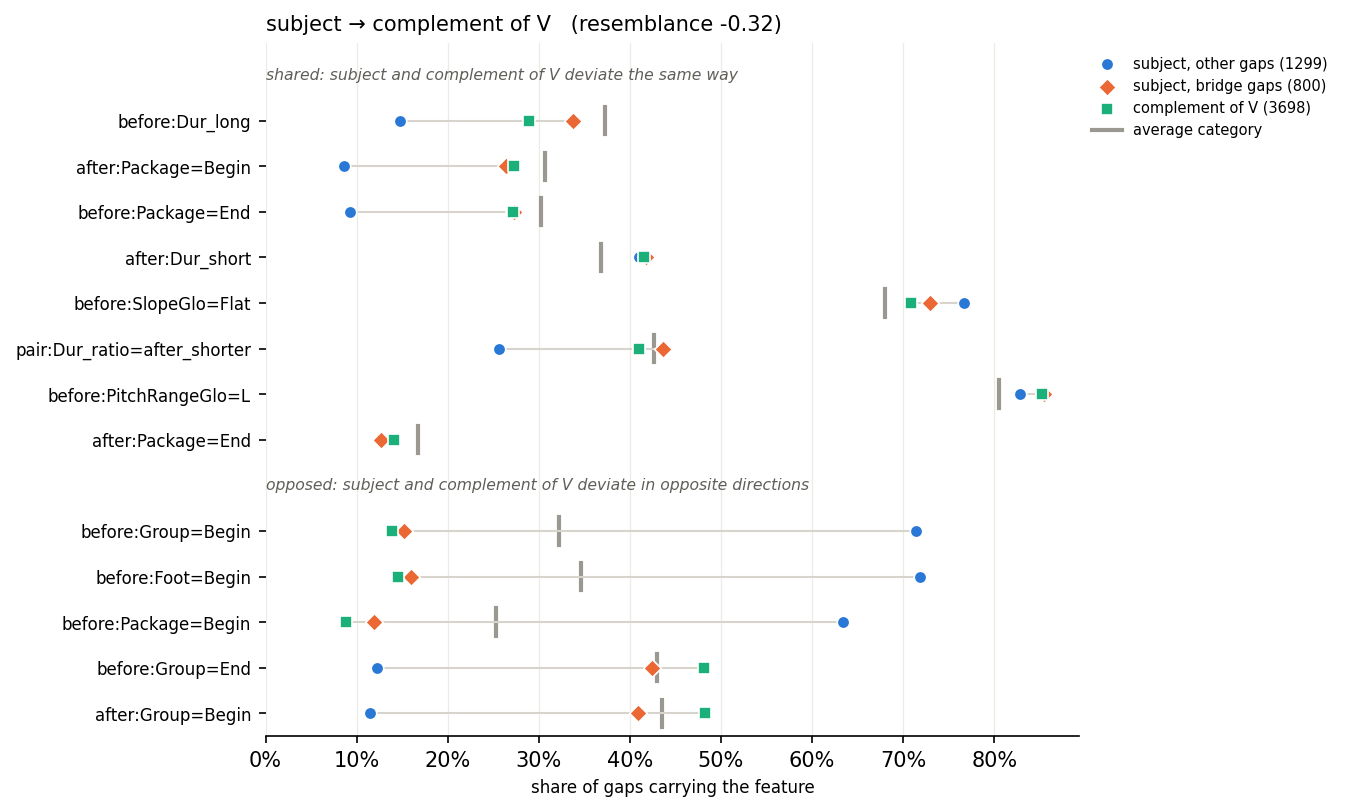

In [71]:
# ── Step 8: what pulls two categories together, and what keeps them apart? ──────
# The word notebook's shared_table() / plot_overlap(), for the categories of Step 5.
# A category's PROFILE = share of its gaps carrying each feature. A feature that almost every
# gap has says nothing about why two categories are close, so each profile is measured as a
# deviation from the AVERAGE CATEGORY (the mean of the profiles, each category counting once):
#     d0(f) = profile_C0(f) − ref(f),   d1(f) = profile_C1(f) − ref(f)
# A feature contributes d0(f) · d1(f) / (|d0| |d1|):
#   > 0  both categories deviate in the same direction       -> shared: pulls them together
#   < 0  they deviate in opposite directions                 -> opposed: keeps them apart
# Summed over all features this is the cosine between d0 and d1 (between −1 and 1).
FEATS = [idx2feature[j] for j in range(GAP_M.shape[1])]
GAP_ROWS = np.where(keep)[0]                                   # GAP_M rows of the Step 5 gaps
_, S_CHOSEN, HAS_CHOSEN = stability(nb_chosen, labels, len(cats))   # p_norm of every gap (Step 4)
PROFILES = np.vstack([GAP_M[GAP_ROWS[labels == c]].mean(0) for c in range(len(cats))])
REF = PROFILES.mean(0)


def variable(f):
    """Values that exclude each other form one variable ('after:Dur_long' -> 'after:Dur',
    'pair:F0_jump=up' -> 'pair:F0_jump'); Begin and End of a unit do not (a one-word Foot is both),
    so each stays a variable of its own."""
    side, rest = f.split(":", 1)
    if rest.endswith(("=Begin", "=End")):
        return f
    return f"{side}:{rest.split('=')[0]}" if "=" in rest else f"{side}:{rest.split('_')[0]}"


def region(f):
    side = f.split(":")[0]
    if side == "pair":
        return "pair"
    return f"{side} / {'acoustic' if any(m in f for m in ('Dur_', 'F0_', 'Glo')) else 'perceptual'}"


REGION = np.array([region(f) for f in FEATS])
REGION_ORDER = ["before / perceptual", "before / acoustic", "pair", "after / acoustic", "after / perceptual"]


def bridge_gaps(c0, c1):
    """Gaps of C0 whose neighbourhood holds at least as much C1 as C0 (and some C1)."""
    a, b = cats.index(c0), cats.index(c1)
    return GAP_ROWS[(labels == a) & HAS_CHOSEN & (S_CHOSEN[:, b] > 0) & (S_CHOSEN[:, b] >= S_CHOSEN[:, a])]


def shared_table(c0, c1):
    d0, d1 = PROFILES[cats.index(c0)] - REF, PROFILES[cats.index(c1)] - REF
    return pd.DataFrame({"feature": FEATS, "variable": [variable(f) for f in FEATS], "region": REGION,
                         "average category": REF, c0: PROFILES[cats.index(c0)], c1: PROFILES[cats.index(c1)],
                         "contrib": d0 * d1 / (np.linalg.norm(d0) * np.linalg.norm(d1))}
                        ).sort_values("contrib", ascending=False)


def region_table(c0, c1):
    """Where the resemblance sits: shared (> 0) and opposed (< 0) parts per region; 'net' sums to the cosine."""
    g = shared_table(c0, c1).groupby("region")["contrib"]
    out = pd.DataFrame({"shared": g.apply(lambda x: x[x > 0].sum()), "opposed": g.apply(lambda x: x[x < 0].sum()),
                        "net": g.sum()}).reindex(REGION_ORDER)
    out.loc["total"] = out.sum()
    return out


COLOURS = {"typical": "#2a78d6", "bridge": "#eb6834", "rival": "#1baf7a"}
MARKERS = {"typical": "o", "bridge": "D", "rival": "s"}


def plot_overlap(c0, c1, k_shared=8, k_opposed=5):
    """One row per feature (one value per variable); x = share of gaps carrying it.
    Top block: features that pull C0 and C1 together; bottom block: features that keep them apart."""
    t = shared_table(c0, c1)
    t = t.loc[t.groupby("variable")["contrib"].apply(lambda s: s.abs().idxmax())]
    shared, opposed = t[t.contrib > 0].nlargest(k_shared, "contrib"), t[t.contrib < 0].nsmallest(k_opposed, "contrib")
    b_ids = bridge_gaps(c0, c1)
    t_ids = np.setdiff1d(GAP_ROWS[labels == cats.index(c0)], b_ids)
    lines = {"typical": GAP_M[t_ids].mean(0), "bridge": GAP_M[b_ids].mean(0) if len(b_ids) else None,
             "rival": PROFILES[cats.index(c1)]}
    names = {"typical": f"{c0}, other gaps ({len(t_ids)})", "bridge": f"{c0}, bridge gaps ({len(b_ids)})",
             "rival": f"{c1} ({(labels == cats.index(c1)).sum()})"}
    fig, ax = plt.subplots(figsize=(7, 0.32 * (len(shared) + len(opposed) + 2) + 1.2), dpi=150)
    y, yt, yl, first = 0, [], [], True
    for header, block in ((f"shared: {c0} and {c1} deviate the same way", shared),
                          (f"opposed: {c0} and {c1} deviate in opposite directions", opposed)):
        if not len(block):
            continue
        ax.annotate(header, (0, y), xycoords=("axes fraction", "data"), fontsize=7.5, color="#5f5e58",
                    style="italic", va="center")
        y += 1
        for _, r in block.iterrows():
            j = FEATS.index(r["feature"])
            ax.plot([REF[j]] * 2, [y - 0.3, y + 0.3], color="#9a9890", lw=2, zorder=1)
            xs = [v[j] for v in lines.values() if v is not None]
            ax.plot([min(xs), max(xs)], [y, y], color="#d6d4cc", lw=1, zorder=1)
            for k, v in lines.items():
                if v is not None:
                    ax.scatter(v[j], y, s=36, color=COLOURS[k], marker=MARKERS[k], edgecolor="white",
                               linewidth=0.8, zorder=3, label=names[k] if first else None)
            first = False
            yt.append(y); yl.append(r["feature"])
            y += 1
    ax.plot([], [], color="#9a9890", lw=2, label="average category")
    ax.set_yticks(yt, yl, fontsize=8)
    ax.set_ylim(y - 0.5, -0.7)
    ax.set_xlim(0, None)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of gaps carrying the feature", fontsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color="#ecebe6", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(f"{c0} → {c1}   (resemblance {region_table(c0, c1).loc['total', 'net']:+.2f})", fontsize=10, loc="left")
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    return fig


def examples(c, n=5):
    for x in GAPS_DF.loc[GAP_ROWS[labels == cats.index(c)], "context"].sample(n, random_state=SEED):
        print("  ·", x)


C0, C1 = "subject", "complement of V"
print(f"resemblance {C0} / {C1}:")
print(region_table(C0, C1).round(3).to_string())
for c in (C0, C1):
    print(f"\n{c}:"); examples(c)
plot_overlap(C0, C1);


resemblance determiner / complement of P:
                     shared  opposed    net
region                                     
before / perceptual   0.266   -0.000  0.266
before / acoustic     0.206   -0.000  0.206
pair                  0.155    0.000  0.155
after / acoustic      0.028   -0.004  0.025
after / perceptual    0.187    0.000  0.187
total                 0.843   -0.004  0.839

determiner:
  · l' activité d' une ‖ pandémie alors euh
  · l' attend à la ‖ gare
  · quand surviennent aussi des ‖ catastrophes naturelles
  · la la ‖ lecture n' était pas
  · et les ‖ malheureux allaient puiser de

complement of P:
  · alors à ‖ la fin de ce
  · j' en suis à ‖ la la vingt~ vingt-deuxième
  · la la secrétaire du ‖ libraire et une et
  · d' environ neuf pour ‖ cent à Paris
  · choisi Yudina euh par ‖ hasard Didier Von Moere


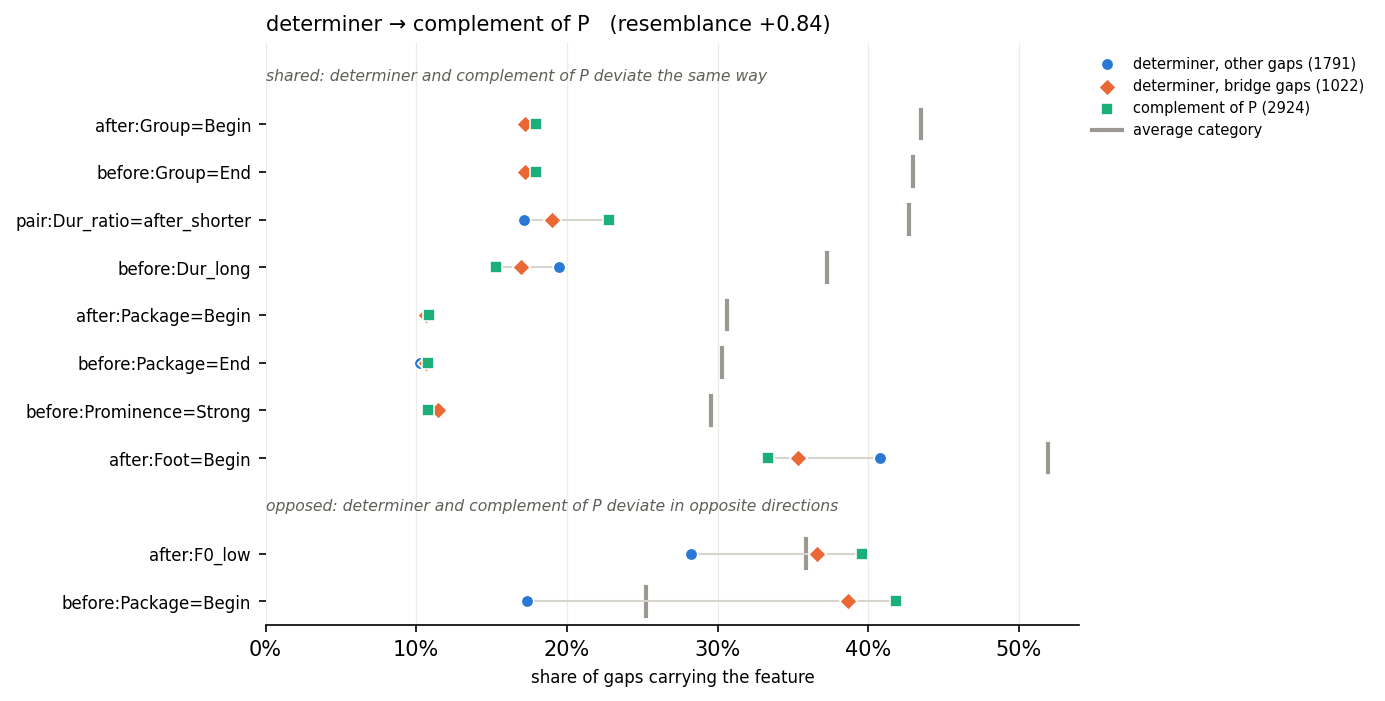

In [73]:
# ── Step 8: what pulls two categories together, and what keeps them apart? ──────
# The word notebook's shared_table() / plot_overlap(), for the categories of Step 5.
# A category's PROFILE = share of its gaps carrying each feature. A feature that almost every
# gap has says nothing about why two categories are close, so each profile is measured as a
# deviation from the AVERAGE CATEGORY (the mean of the profiles, each category counting once):
#     d0(f) = profile_C0(f) − ref(f),   d1(f) = profile_C1(f) − ref(f)
# A feature contributes d0(f) · d1(f) / (|d0| |d1|):
#   > 0  both categories deviate in the same direction       -> shared: pulls them together
#   < 0  they deviate in opposite directions                 -> opposed: keeps them apart
# Summed over all features this is the cosine between d0 and d1 (between −1 and 1).
# CHANGED: works on any categorisation of the Step 5 gaps — call view() first (see the end of the cell).
FEATS = [idx2feature[j] for j in range(GAP_M.shape[1])]
GAP_ROWS = np.where(keep)[0]                                   # GAP_M rows of the Step 5 gaps
REFERENCE = "average category"     # or "all gaps": then a category's profile no longer depends on the others
 
 
def view(lab, names):
    """Choose the categorisation Step 8 looks at: lab[i] = category number of gap GAP_ROWS[i]."""
    global VIEW_LAB, VIEW_CATS, S_VIEW, HAS_VIEW, PROFILES, REF
    VIEW_LAB, VIEW_CATS = np.asarray(lab), list(names)
    _, S_VIEW, HAS_VIEW = stability(nb_chosen, VIEW_LAB, len(VIEW_CATS))     # p_norm of every gap (Step 4)
    PROFILES = np.vstack([GAP_M[GAP_ROWS[VIEW_LAB == c]].mean(0) for c in range(len(VIEW_CATS))])
    REF = PROFILES.mean(0) if REFERENCE == "average category" else GAP_M[GAP_ROWS].mean(0)
 
 
def characterise(c, k=8):
    """The k features on which category c departs most from the reference, in percentage points."""
    d = pd.Series(100 * (PROFILES[VIEW_CATS.index(c)] - REF), index=FEATS)
    return d.reindex(d.abs().sort_values(ascending=False).index).head(k).round(0)
 
 
def variable(f):
    """Values that exclude each other form one variable ('after:Dur_long' -> 'after:Dur',
    'pair:F0_jump=up' -> 'pair:F0_jump'); Begin and End of a unit do not (a one-word Foot is both),
    so each stays a variable of its own."""
    side, rest = f.split(":", 1)
    if rest.endswith(("=Begin", "=End")):
        return f
    return f"{side}:{rest.split('=')[0]}" if "=" in rest else f"{side}:{rest.split('_')[0]}"
 
 
def region(f):
    side = f.split(":")[0]
    if side == "pair":
        return "pair"
    return f"{side} / {'acoustic' if any(m in f for m in ('Dur_', 'F0_', 'Glo')) else 'perceptual'}"
 
 
REGION = np.array([region(f) for f in FEATS])
REGION_ORDER = ["before / perceptual", "before / acoustic", "pair", "after / acoustic", "after / perceptual"]
 
 
def bridge_gaps(c0, c1):
    """Gaps of C0 whose neighbourhood holds at least as much C1 as C0 (and some C1)."""
    a, b = VIEW_CATS.index(c0), VIEW_CATS.index(c1)
    return GAP_ROWS[(VIEW_LAB == a) & HAS_VIEW & (S_VIEW[:, b] > 0) & (S_VIEW[:, b] >= S_VIEW[:, a])]
 
 
def shared_table(c0, c1):
    d0, d1 = PROFILES[VIEW_CATS.index(c0)] - REF, PROFILES[VIEW_CATS.index(c1)] - REF
    return pd.DataFrame({"feature": FEATS, "variable": [variable(f) for f in FEATS], "region": REGION,
                         "average category": REF, c0: PROFILES[VIEW_CATS.index(c0)], c1: PROFILES[VIEW_CATS.index(c1)],
                         "contrib": d0 * d1 / (np.linalg.norm(d0) * np.linalg.norm(d1))}
                        ).sort_values("contrib", ascending=False)
 
 
def region_table(c0, c1):
    """Where the resemblance sits: shared (> 0) and opposed (< 0) parts per region; 'net' sums to the cosine."""
    g = shared_table(c0, c1).groupby("region")["contrib"]
    out = pd.DataFrame({"shared": g.apply(lambda x: x[x > 0].sum()), "opposed": g.apply(lambda x: x[x < 0].sum()),
                        "net": g.sum()}).reindex(REGION_ORDER)
    out.loc["total"] = out.sum()
    return out
 
 
COLOURS = {"typical": "#2a78d6", "bridge": "#eb6834", "rival": "#1baf7a"}
MARKERS = {"typical": "o", "bridge": "D", "rival": "s"}
 
 
def plot_overlap(c0, c1, k_shared=8, k_opposed=5):
    """One row per feature (one value per variable); x = share of gaps carrying it.
    Top block: features that pull C0 and C1 together; bottom block: features that keep them apart."""
    t = shared_table(c0, c1)
    t = t.loc[t.groupby("variable")["contrib"].apply(lambda s: s.abs().idxmax())]
    shared, opposed = t[t.contrib > 0].nlargest(k_shared, "contrib"), t[t.contrib < 0].nsmallest(k_opposed, "contrib")
    b_ids = bridge_gaps(c0, c1)
    t_ids = np.setdiff1d(GAP_ROWS[VIEW_LAB == VIEW_CATS.index(c0)], b_ids)
    lines = {"typical": GAP_M[t_ids].mean(0), "bridge": GAP_M[b_ids].mean(0) if len(b_ids) else None,
             "rival": PROFILES[VIEW_CATS.index(c1)]}
    names = {"typical": f"{c0}, other gaps ({len(t_ids)})", "bridge": f"{c0}, bridge gaps ({len(b_ids)})",
             "rival": f"{c1} ({(VIEW_LAB == VIEW_CATS.index(c1)).sum()})"}
    fig, ax = plt.subplots(figsize=(7, 0.32 * (len(shared) + len(opposed) + 2) + 1.2), dpi=150)
    y, yt, yl, first = 0, [], [], True
    for header, block in ((f"shared: {c0} and {c1} deviate the same way", shared),
                          (f"opposed: {c0} and {c1} deviate in opposite directions", opposed)):
        if not len(block):
            continue
        ax.annotate(header, (0, y), xycoords=("axes fraction", "data"), fontsize=7.5, color="#5f5e58",
                    style="italic", va="center")
        y += 1
        for _, r in block.iterrows():
            j = FEATS.index(r["feature"])
            ax.plot([REF[j]] * 2, [y - 0.3, y + 0.3], color="#9a9890", lw=2, zorder=1)
            xs = [v[j] for v in lines.values() if v is not None]
            ax.plot([min(xs), max(xs)], [y, y], color="#d6d4cc", lw=1, zorder=1)
            for k, v in lines.items():
                if v is not None:
                    ax.scatter(v[j], y, s=36, color=COLOURS[k], marker=MARKERS[k], edgecolor="white",
                               linewidth=0.8, zorder=3, label=names[k] if first else None)
            first = False
            yt.append(y); yl.append(r["feature"])
            y += 1
    ax.plot([], [], color="#9a9890", lw=2, label="average category")
    ax.set_yticks(yt, yl, fontsize=8)
    ax.set_ylim(y - 0.5, -0.7)
    ax.set_xlim(0, None)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of gaps carrying the feature", fontsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color="#ecebe6", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(f"{c0} → {c1}   (resemblance {region_table(c0, c1).loc['total', 'net']:+.2f})", fontsize=10, loc="left")
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    return fig
 
 
def examples(c, n=5):
    for x in GAPS_DF.loc[GAP_ROWS[VIEW_LAB == VIEW_CATS.index(c)], "context"].sample(n, random_state=SEED):
        print("  ·", x)
 
 
view(labels, cats)                     # Step 5's categories
# view(ref_labels, REF_CATS)            # or Step 7's refined categories
C0, C1 = "determiner", "complement of P"
print(f"resemblance {C0} / {C1}:")
print(region_table(C0, C1).round(3).to_string())
for c in (C0, C1):
    print(f"\n{c}:"); examples(c)
plot_overlap(C0, C1);

## Step 9 (optional) — which categories can prosody tell apart?
**Pairwise κ.** For two categories A and B, take only their gaps, find each gap's 20 nearest neighbours among them, and compute κ as in Step 4. With two categories, chance is 0.5, so κ = (stability − 0.5) / 0.5:
* κ = 0: a gap's neighbours are as mixed as after shuffling the labels, so prosody cannot tell A from B;
* κ = 0.20: 60% of its neighbours are in its own category instead of 50%;
* κ = 1: all of them are.

**The tree.** The two categories with the lowest κ are joined first, then the next lowest, and so on. When a branch holds several categories, its κ with another branch is the mean of the pairwise κ between their categories (average linkage). The x-axis gives the κ at which two branches join: far left means prosodically almost identical, far right means clearly different.

**Reading it.** Only the branching matters. Two categories are close if they join near the left, wherever they sit on the page; the leaves are ordered only so that branches do not cross. The dashed line is `KAPPA_MIN` = 0.20, the threshold of the split test (Step 6). The branches that join to its left are categories prosody does not reliably separate, and each such group gets its own colour. Joins to the right of the line show how far apart the groups are. A category with grey lines joins nothing below 0.20.

21 categories, 210 pairs tested in 26s
group 1 (1521 gaps): disfluency →, periphery ←
group 2 (8792 gaps): complement of V →, complement of other →, modifier of N ←, modifier of N →, modifier of V ←, modifier of V →, modifier of other ←, modifier of other →, udep →
group 3 (59 gaps): subject →
group 4 (626 gaps): coordination / apposition →
group 5 (1089 gaps): periphery →
group 6 (1288 gaps): complement of C →, coordination / apposition ←
group 7 (8268 gaps): complement of P →, complement of V ←, determiner ←, subject ←
group 8 (258 gaps): flat / compound →


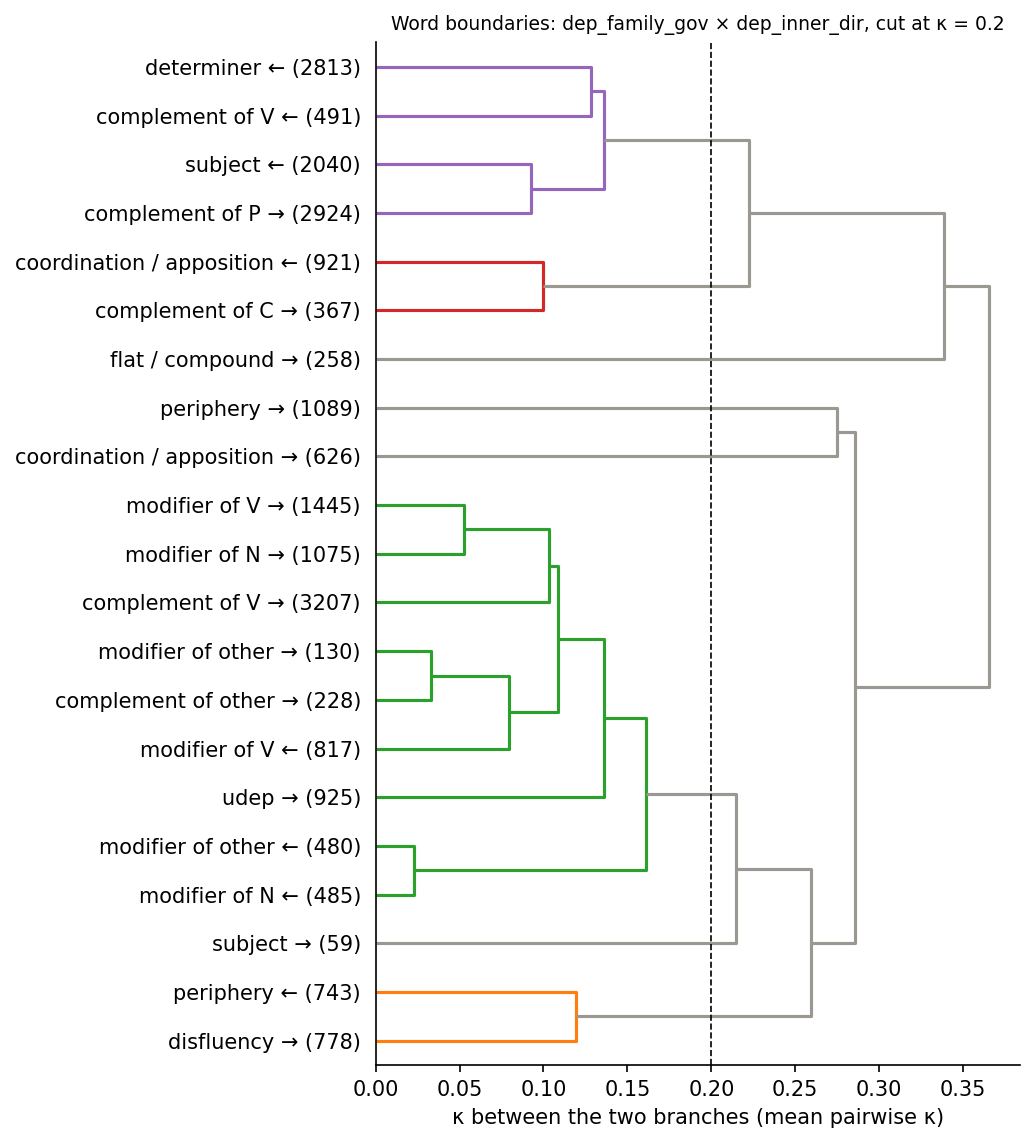

In [74]:
# ── Step 9 (optional): which categories can prosody tell apart? ───────────────
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

TREE_ON = ("dep_family_gov", "dep_inner_dir")             # leaves: family × governor × direction
WORD_BOUNDARIES = (GAPS_DF["gap_type"] == "word boundary").to_numpy()


def pair_kappa(cols, mask):
    """κ for every pair of categories: the two categories' gaps alone, neighbours recomputed among them."""
    lab = GAPS_DF[list(cols)].astype(str).agg(" ".join, axis=1).to_numpy()
    lab[~mask] = ""
    names = sorted(c for c, n in Counter(lab[mask]).items() if n >= MIN_CAT)
    rng_ = np.random.default_rng(SEED)
    K = pd.DataFrame(0.0, index=names, columns=names)
    for a, b in combinations(names, 2):
        rows_ = np.where((lab == a) | (lab == b))[0]
        nb_ = gap_neighbours(GAP_M[rows_], rng_)
        K.loc[a, b] = K.loc[b, a] = kappa_test(nb_, (lab[rows_] == b).astype(int), 2, N_PERM_RANK, rng_)["kappa"]
    return K, Counter(lab[mask])


t0 = time.time()
PAIR_K, sizes = pair_kappa(TREE_ON, WORD_BOUNDARIES)
print(f"{len(PAIR_K)} categories, {len(PAIR_K) * (len(PAIR_K) - 1) // 2} pairs tested in {time.time() - t0:.0f}s")

TREE = linkage(squareform(PAIR_K.clip(lower=0).to_numpy(), checks=False), method="average")
GROUP_OF = dict(zip(PAIR_K.index, fcluster(TREE, t=KAPPA_MIN, criterion="distance")))
for g in sorted(set(GROUP_OF.values())):
    members = [c for c, x in GROUP_OF.items() if x == g]
    print(f"group {g} ({sum(sizes[c] for c in members)} gaps): " + ", ".join(members))

fig, ax = plt.subplots(figsize=(7, 0.32 * len(PAIR_K) + 1), dpi=150)
dendrogram(TREE, labels=[f"{c} ({sizes[c]})" for c in PAIR_K.index], orientation="right",
           color_threshold=KAPPA_MIN, above_threshold_color="#9a9890", ax=ax)
ax.axvline(KAPPA_MIN, ls="--", c="k", lw=0.8)
ax.set_xlabel("κ between the two branches (mean pairwise κ)")
ax.set_title(f"Word boundaries: {' × '.join(TREE_ON)}, cut at κ = {KAPPA_MIN}", fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()


In [75]:
# ═══ (D) optional, a new cell after Step 9 — test the dendrogram's groups like any other categorisation ═══
lab = GAPS_DF["dep_family_gov"] + " " + GAPS_DF["dep_inner_dir"]
GAPS_DF["dep_grouped"] = lab.map({c: f"group {g}" for c, g in GROUP_OF.items()}).fillna("rare")
GAPS_DF.loc[~WORD_BOUNDARIES, "dep_grouped"] = "inside a word"
# then go back to Step 5 and run it with CHOSEN = ("dep_grouped",)

In [ ]:
# in order to get the names of the actual categories in the stability matrix, rather than group 1, 2, 3 etc., run the following cell after Step 9:
leaf = GAPS_DF[list(TREE_ON)].astype(str).agg(" ".join, axis=1)
members = {g: [c for c, x in GROUP_OF.items() if x == g] for g in sorted(set(GROUP_OF.values()))}
name = {g: " + ".join(m) if len(m) <= 3 else " + ".join(m[:3]) + f" (+{len(m) - 3})" for g, m in members.items()}
GAPS_DF["dep_grouped"] = leaf.map({c: name[g] for c, g in GROUP_OF.items()}).fillna("rare")
GAPS_DF.loc[~WORD_BOUNDARIES, "dep_grouped"] = "inside a word"
for g, m in members.items():
    print(f"{name[g]}  =  {', '.join(m)}")
# then go back to Step 5 and run it with CHOSEN = ("dep_grouped",)

## Step 10 — can prominence be recovered from the acoustics alone?
The same method as for the gaps, applied to syllables.
* **Unit**: one syllable, kept when:
  * it is the first or the last syllable of its word (only those carry a prominence label);
  * its label is 0, Weak or Strong (Overlap and Pause are left out);
  * it and the syllables before and after it are fully measured.
* **Vector**: the acoustic features of Step 1 (binned duration, F0 from the utterance mean, height, pitch range and slope) for the syllable, the previous syllable and the next syllable, since prominence is relative to its context. The third space adds:
  * the syllable's SLAM contour (`Glo`);
  * its loudness (amplitude minus the utterance mean, in tertiles);
  * the pauses around its word (`NextBreakLength` on the word before a pause).
* **Test**: neighbours as in Step 3. κ is computed for two categorisations: prominent or not, and none / Weak / Strong. *right* = the share of each category whose neighbours point to it, as in `neighbour_guess()`.

In [76]:
# ── Step 10: can prominence be recovered from the acoustics alone? ──────────────
# Same method as everywhere else, applied to syllables: each syllable is a 0/1 vector of acoustic
# features, its 20 nearest neighbours are found, and we ask how often they share its prominence label.
def measured_syllable(sy):
    """The syllable has every acoustic measure of Step 1."""
    return all((_number(sy["misc"].get(n)) is not None) if n in BIN_LABELS
               else sy["misc"].get(n) not in (None, "X") for n in ACOUSTIC_MEASURES)


def extras(s, k, t, first, last, amp_bins):
    """SLAM contour of the syllable, its loudness, and the pauses around its word (NextBreakLength)."""
    sy, out = s["syllables"][k], []
    if sy["misc"].get("Glo") not in (None, "X"):
        out.append(f"own:Glo={sy['misc']['Glo']}")                      # SLAM contour of the syllable
    a = _number(sy["misc"].get("AvgAmplitude"))
    if a is not None and amp_bins is not None:
        out.append(f"own:Loud={['low', 'mid', 'high'][int(np.searchsorted(amp_bins, a - s['amp_mean']))]}")
    tok = s["tokens"]
    if last and _number(tok[t]["misc"].get("NextBreakLength")):
        out.append("pause after the word")
    if first and t - 1 in tok and _number(tok[t - 1]["misc"].get("NextBreakLength")):
        out.append("pause before the word")
    return out


# loudness = amplitude minus the utterance's mean amplitude (raw amplitude depends on the recording)
for s in SENTS:
    amps = [a for sy in s["syllables"] if (a := _number(sy["misc"].get("AvgAmplitude"))) is not None]
    s["amp_mean"] = np.mean(amps) if amps else np.nan
rel_amp = [a - s["amp_mean"] for s in SENTS for sy in s["syllables"] if (a := _number(sy["misc"].get("AvgAmplitude"))) is not None]
AMP_BINS = np.quantile(rel_amp, [1 / 3, 2 / 3])

SYL_INFO, SYL_FEATS, skipped_syl = [], [], Counter()
for s in SENTS:
    syl, tok = s["syllables"], s["tokens"]
    for k, sy in enumerate(syl):
        t = max(sy["toks"])
        if t not in tok:
            continue
        first, last = s["first"][t] == k, s["last"][t] == k
        label = tok[t]["misc"].get("ProminenceFinal" if last else "ProminenceInitial")
        if not (first or last):
            skipped_syl["inside a word (never annotated)"] += 1
        elif label in (None, "Overlap", "Pause"):
            skipped_syl[f"label {label}"] += 1
        elif not all(measured_syllable(syl[j]) for j in (k - 1, k, k + 1) if 0 <= j < len(syl)):
            skipped_syl["not fully measured"] += 1
        else:
            feats = [f"own:{f}" for f in acoustic(sy)]
            for side, j in (("prev", k - 1), ("next", k + 1)):
                feats += [f"{side}:{f}" for f in acoustic(syl[j])] if 0 <= j < len(syl) else [f"{side}:none"]
            feats += extras(s, k, t, first, last, AMP_BINS)
            p = prominence(s, k)                                         # Step 1: Weak, Strong or None
            SYL_INFO.append(dict(sent_id=s["sent_id"], word=tok[t]["form"], syllable=sy["misc"].get("SylForm"),
                                 upos=tok[t]["upos"],
                                 word_class="function" if tok[t]["upos"] in FUNCTION_POS else "content",
                                 position="only" if first and last else "last" if last else "first",
                                 prominence=p or "none"))
            SYL_FEATS.append(feats)
SYL_DF = pd.DataFrame(SYL_INFO)
print(f"{len(SYL_DF)} syllables kept | skipped: {dict(skipped_syl)}")
print(SYL_DF.prominence.value_counts().to_string())

EXTRA = ("own:Glo", "own:Loud", "pause")
syl_counts = Counter(f for fs in SYL_FEATS for f in set(fs))
syl_kept = sorted(f for f, n in syl_counts.items() if n >= MIN_FEATURE_OCC)
SYL_M_ALL = np.zeros((len(SYL_FEATS), len(syl_kept)), dtype=np.float32)
for a, fs in enumerate(SYL_FEATS):
    for f in fs:
        if f in syl_kept:
            SYL_M_ALL[a, syl_kept.index(f)] = 1
SYL_SPACES = {
    "own syllable": [j for j, f in enumerate(syl_kept) if f.startswith("own:") and not f.startswith(EXTRA)],
    "own + previous + next syllable": [j for j, f in enumerate(syl_kept) if not f.startswith(EXTRA)],
    "+ contour, loudness, pauses": list(range(len(syl_kept))),
}
print({k: len(v) for k, v in SYL_SPACES.items()}, "features")


29488 syllables kept | skipped: {'not fully measured': 8913, 'inside a word (never annotated)': 4236, 'label Pause': 830, 'label None': 256, 'label Overlap': 104}
prominence
none      15234
Strong     8640
Weak       5614
{'own syllable': 15, 'own + previous + next syllable': 47, '+ contour, loudness, pauses': 81} features


In [77]:
# Two questions per space: prominent or not (2 categories), and none / Weak / Strong (3 categories).
# "guessed right" = the category the neighbours point to most (p_norm, as in Step 4), per category.
PROM = (SYL_DF.prominence != "none").to_numpy().astype(int)
PROM3_NAMES = ["none", "Weak", "Strong"]
PROM3 = SYL_DF.prominence.map({c: i for i, c in enumerate(PROM3_NAMES)}).to_numpy()


def guessed_right(nb, lab, n_cats):
    _, S, has = stability(nb, lab, n_cats)
    guess = S.argmax(1)
    return [(guess[has & (lab == c)] == c).mean() for c in range(n_cats)]


rows_, SYL_NB = [], {}
for space, cols in SYL_SPACES.items():
    nb = gap_neighbours(SYL_M_ALL[:, cols], np.random.default_rng(SEED))
    SYL_NB[space] = nb
    k2 = kappa_test(nb, PROM, 2, N_PERM_RANK, np.random.default_rng(SEED))
    k3 = kappa_test(nb, PROM3, 3, N_PERM_RANK, np.random.default_rng(SEED))
    g2, g3 = guessed_right(nb, PROM, 2), guessed_right(nb, PROM3, 3)
    rows_.append({"space": space, "features": len(cols),
                  "κ prominent/not": k2["kappa"], "right: not prominent": g2[0], "right: prominent": g2[1],
                  "κ none/Weak/Strong": k3["kappa"], "right: none": g3[0], "right: Weak": g3[1], "right: Strong": g3[2]})
PROM_TABLE = pd.DataFrame(rows_).set_index("space")
with pd.option_context("display.width", 250):
    print(PROM_TABLE.round(3).to_string())


                                features  κ prominent/not  right: not prominent  right: prominent  κ none/Weak/Strong  right: none  right: Weak  right: Strong
space                                                                                                                                                         
own syllable                          15            0.247                 0.731             0.677               0.164        0.606        0.358          0.589
own + previous + next syllable        47            0.281                 0.778             0.676               0.200        0.651        0.416          0.602
+ contour, loudness, pauses           81            0.285                 0.784             0.672               0.204        0.645        0.432          0.596


### Where do the annotation and the acoustics disagree? (for the prosody paper)
For each syllable, the share of its 20 acoustic neighbours that were marked prominent estimates how likely the acoustics alone make a prominence. Averaged over a group of syllables, it gives the rate the acoustics would predict. *difference* = annotated rate − that rate.

In [78]:
# Where do the annotators and the acoustics disagree? For every syllable, "acoustic neighbours" =
# share of its 20 nearest acoustic neighbours (own + previous + next syllable) marked prominent.
# Averaged over a group of syllables, it is the prominence rate the acoustics alone would predict.
rows, nbr, w = SYL_NB["own + previous + next syllable"]
SYL_DF["acoustic neighbours"] = np.bincount(rows, weights=w * PROM[nbr], minlength=len(PROM))
SYL_DF["annotated"] = PROM
BY_CLASS = (SYL_DF.groupby(["word_class", "position"])
            .agg(syllables=("annotated", "size"), annotated=("annotated", "mean"),
                 acoustic_neighbours=("acoustic neighbours", "mean")))
BY_CLASS["difference"] = BY_CLASS.annotated - BY_CLASS.acoustic_neighbours
print(BY_CLASS.round(3).to_string())


                     syllables  annotated  acoustic_neighbours  difference
word_class position                                                       
content    first          6342      0.335                0.396      -0.061
           last           6287      0.839                0.661       0.178
           only           5960      0.668                0.566       0.101
function   first           602      0.183                0.337      -0.154
           last            512      0.451                0.453      -0.002
           only           9785      0.259                0.349      -0.090
